# Module 10 · Classifiers: Predicting Treatment Response from Gene Expression
**Student:** Awo Abdillahi  
**Student ID:** 1001911900  

### Two-class sequence · Lecture 1 (models) → Lecture 2 (evaluation)

**Biological question:** *Can pretreatment gene-expression measurements predict whether a tumor will respond to therapy?*

The data labels are **Responder (0)** and **Nonresponder (1)**.

This notebook builds on our earlier supervised (regression) and unsupervised (PCA/clustering) exercises. We briefly introduce **t-SNE and UMAP** as additional unsupervised visualization methods, then compare **Logistic Regression, Support Vector Machines (SVM), and Random Forests**. Lecture 2 assesses whether those predictions generalize.

**Data:** 600 simulated tumors × 80 simulated normalized expression measurements, with measured binary treatment response and a technical batch effect. The label is a treatment *outcome*, the nonresponder class is simulated to be less common, as is typical at the drug-trial stage.

**Learning Objectives**
1. Contrast PCA, t-SNE, and UMAP; explain why an unsupervised projection does not prove biological subtypes.
2. Explain and visualize Logistic Regression, RBF SVM (`C`, `gamma`), and Random Forest.
3. Perform stratified splitting, leakage-safe Pipelines, StratifiedKFold, and GridSearchCV.
4. Interpret TN / FP / FN / TP, sensitivity (recall), specificity, precision, F1, ROC-AUC, and average precision (PR) for a named positive class.
5. Select models and thresholds without using held-out test labels; separate predictive association from causal inference.

**Assignment:** Answer each **Predict** prompt *before* the next code cell, and **Explain** using its output. Edit the **_Your response here_** text in the existing Markdown cells—**do not add new cells**. Save your executed notebook and submit the GitHub links in Canvas.

**Pacing:** Lecture 1: Sections 0–5, including t-SNE/UMAP context. Lecture 2: Sections 6–10, including validation, threshold selection, ROC and PR curves.


## 0) Setup and reproducibility
This notebook uses NumPy, pandas, matplotlib, scipy, and scikit-learn. **UMAP is optional**, because it uses a separate package. In Colab, the setup cell installs it if necessary; outside Colab, the other exercises still run if UMAP is unavailable.

In [ ]:
import sys, importlib.util, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if importlib.util.find_spec('umap') is None and IN_COLAB:
    print('Installing optional UMAP package in Colab (once per runtime)...')
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'umap-learn'])

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import expit
from pathlib import Path
from IPython.display import display
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, classification_report
)

SEED = 42
BLUE, ORANGE, GREEN, PURPLE = '#0072B2', '#D55E00', '#009E73', '#CC79A7'
plt.rcParams.update({'figure.dpi':105,'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False})
OUT = Path('classifier_outputs'); OUT.mkdir(exist_ok=True)

def finish(filename):
    plt.tight_layout()
    plt.savefig(OUT / f'{filename}.png', dpi=150, bbox_inches='tight')
    plt.show()

def metrics(y_true, prediction):
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0,1]).ravel()
    return {'accuracy':accuracy_score(y_true,prediction),
            'balanced_accuracy':balanced_accuracy_score(y_true,prediction),
            'sensitivity / recall':recall_score(y_true,prediction,zero_division=0),
            'specificity':tn/(tn+fp),
            'precision':precision_score(y_true,prediction,zero_division=0),
            'F1':f1_score(y_true,prediction,zero_division=0),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

def show_cm(ax, truth, predictions, title):
    ConfusionMatrixDisplay.from_predictions(
        truth, predictions, labels=[0,1], display_labels=['Responder','Nonresponder'],
        cmap='Blues', colorbar=False, ax=ax, values_format='d')
    ax.set_title(title)

print('Python:',sys.version.split()[0], '| scikit-learn:',sklearn.__version__)

Python: 3.13.5 | scikit-learn: 1.8.0


## 1) Define the problem: samples, features, and labels **(Slides 1-6)**

In unsupervised learning we explored expression structure *without* known labels. Here the scientific question is supervised: given expression and **observed treatment response** for training tumors, can we predict outcomes for new tumors?

The simulated dataset has **600 tumors × 80 expression features**, with **Responder (0)** more common than **Nonresponder (1)**. A **technical batch effect** changes some expression features but is not programmed to cause the treatment outcome. Batch is not an input to the classifiers.

We split the data into **TRAIN (60%)**, **VALIDATION (20%)**, and untouched **TEST (20%)** before modeling.

* **Stratification** *preserves the response proportions in each partition.*


**Predict (before running):** What label would an always-Responder baseline assign to every tumor? Could it have reasonably high **accuracy** while detecting **zero nonresponders**? What would its statistical **sensitivity** be for the nonresponder class?

**Your response:** I expect the baseline to label all 600 tumors as Responders (0), regardless of their gene expression. Because Responders make up roughly 78% of this dataset, the overall accuracy could look respectable even though the model never identifies a single Nonresponder. Its sensitivity for Nonresponders would be 0/(TP+FN) = 0. The training output confirms 0.778 accuracy and zero sensitivity, demonstrating why accuracy alone is misleading.


In [ ]:
rng = np.random.default_rng(53)
n, p = 600, 80
program_a = rng.normal(size=n)
program_b = rng.normal(size=n)
batch = rng.integers(0,2,size=n)

# Simulated continuous normalized/log-like expression: NOT read counts.
gene_baselines = rng.normal(6.0,0.45,p)
X_all = gene_baselines + rng.normal(0, 0.95, size=(n,p))
X_all[:, 0:15] += 0.95*program_a[:,None]
X_all[:,15:30] += 0.90*program_b[:,None]
X_all[:,30:40] += 0.36*program_a[:,None] - 0.30*program_b[:,None]
X_all[:,45:70] += 2.00*batch[:,None]  # independent batch-driven expression

# Latent biology changes odds of nonresponse; neither response nor batch is a feature.
nonresponse_prob = expit(-2.25 + 1.60*program_a - 1.45*program_b
                        + 0.35*program_a*program_b)
y_all = rng.binomial(1, nonresponse_prob)
GENES = [f'Gene_{i+1:02d}' for i in range(p)]
ids = np.arange(n)

trainval_idx, test_idx = train_test_split(ids, test_size=0.20,
        stratify=y_all, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=0.25,
        stratify=y_all[trainval_idx], random_state=SEED)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

assert len(set(train_idx)&set(test_idx)) == 0
assert len(set(train_idx)&set(val_idx)) == 0
print('TRAIN: ',X_train.shape, '  VAL: ',X_val.shape,'  TEST (do not inspect yet): ',X_test.shape)
print('Train class proportions:',pd.Series(y_train).map({0:'Responder',1:'Nonresponder'}).value_counts(normalize=True).round(3).to_dict())
display(pd.DataFrame(X_train[:4,:6], columns=GENES[:6]).round(2))
print('Always-Responder TRAINING accuracy:',round((y_train==0).mean(),3))
print('Always-Responder sensitivity for nonresponders:',0.0)

TRAIN:  (360, 80)   VAL:  (120, 80)   TEST (do not inspect yet):  (120, 80)
Train class proportions: {'Responder': 0.778, 'Nonresponder': 0.222}


,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06
0,7.00,5.92,6.85,5.68,5.36,7.99
1,8.30,5.95,6.42,7.85,7.61,8.18
2,8.54,4.94,6.55,5.89,4.92,5.39
3,8.23,9.01,8.60,7.00,6.23,7.62


Always-Responder TRAINING accuracy: 0.778
Always-Responder sensitivity for nonresponders: 0.0


In [ ]:
### Uncomment the line below to visulaize the dataframe with features and label data stitched together. ###
display(pd.DataFrame(X_train, columns=GENES).assign(Response=np.where(y_train == 1, "Nonresponder", "Responder"), Batch=np.asarray(batch)[train_idx]))

,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06,Gene_07,Gene_08,Gene_09,Gene_10,Gene_11,Gene_12,Gene_13,Gene_14,Gene_15,Gene_16,Gene_17,Gene_18,Gene_19,Gene_20,Gene_21,Gene_22,Gene_23,Gene_24,Gene_25,Gene_26,Gene_27,Gene_28,Gene_29,Gene_30,Gene_31,Gene_32,Gene_33,Gene_34,Gene_35,Gene_36,Gene_37,Gene_38,Gene_39,Gene_40,...,Gene_43,Gene_44,Gene_45,Gene_46,Gene_47,Gene_48,Gene_49,Gene_50,Gene_51,Gene_52,Gene_53,Gene_54,Gene_55,Gene_56,Gene_57,Gene_58,Gene_59,Gene_60,Gene_61,Gene_62,Gene_63,Gene_64,Gene_65,Gene_66,Gene_67,Gene_68,Gene_69,Gene_70,Gene_71,Gene_72,Gene_73,Gene_74,Gene_75,Gene_76,Gene_77,Gene_78,Gene_79,Gene_80,Response,Batch
0,7.004987,5.919840,6.848830,5.679245,5.355597,7.994914,6.875984,7.989813,6.655276,5.908140,5.386899,6.863157,6.553203,6.142917,5.353008,6.340811,4.089624,5.328237,5.552100,6.048997,6.725760,6.362907,6.223477,5.312275,5.039469,7.225647,6.025059,7.564737,4.345881,4.181883,7.512009,6.318413,6.804623,6.162399,5.970789,5.941803,7.455363,5.851806,7.103260,8.285463,...,6.320134,7.094077,5.495619,6.987907,6.081638,6.230603,6.469902,8.652226,4.413043,6.616399,7.143365,6.475897,6.350990,3.770267,4.266432,7.409215,5.892716,5.561916,6.609348,8.462365,6.227972,5.995667,5.565071,7.493276,6.858865,5.650218,5.212842,5.649990,7.265571,7.224028,5.760716,5.936805,7.772154,6.869916,7.787910,5.931004,5.944981,4.616152,Responder,0
1,8.300304,5.950817,6.424523,7.849450,7.609624,8.180811,6.742865,7.613485,6.487845,6.571483,6.842000,7.604020,5.218009,6.967234,5.015771,6.129453,6.532646,8.150196,9.283416,7.110982,7.034009,7.613598,5.367327,6.196094,6.127029,8.650283,7.449913,7.984943,6.900217,7.867534,6.835727,5.600244,4.588867,6.456446,5.226237,5.018784,7.927341,4.965745,6.399047,5.616467,...,4.655547,6.526618,6.601583,6.747808,5.871503,7.632210,6.849627,5.918176,7.048261,6.668692,7.223333,6.620851,7.948336,3.870884,4.948196,6.384839,7.889754,7.003541,7.972468,5.893970,5.995142,5.072604,5.702761,6.353726,7.404837,6.212221,6.224578,7.741730,5.605288,5.081887,5.878862,6.388857,7.049336,8.805764,6.634344,5.055151,6.830811,5.436944,Responder,0
2,8.539952,4.941443,6.554839,5.894486,4.916984,5.389568,7.196361,5.061244,5.169256,3.632834,4.249343,4.457631,5.671475,3.582067,3.993445,7.863891,7.168599,7.906192,10.067621,9.152593,9.119281,9.530995,6.891642,8.890077,8.170196,9.010347,9.926250,8.405318,8.916689,6.863497,6.629121,4.421402,4.229387,5.498557,3.531712,4.665294,5.239252,3.649635,4.287576,6.042558,...,6.820158,4.511882,6.730509,5.360166,6.265955,7.444912,5.587596,4.596944,4.450496,7.071332,5.879472,5.559346,6.126989,5.562700,7.660103,7.029508,5.467274,5.546424,5.425212,6.962019,7.243828,6.652408,5.514406,6.431115,6.026837,5.723161,5.000440,4.465953,7.477058,5.449028,6.637483,8.208212,5.187800,5.587994,6.114678,5.206840,8.437442,7.156050,Responder,0
3,8.229490,9.011928,8.601539,7.003099,6.231945,7.617015,6.101111,5.842449,6.601932,6.971283,6.339448,6.086655,5.904390,5.819829,5.971761,4.206390,7.751291,6.792603,7.686903,6.414091,5.151673,6.763208,5.101195,7.170652,6.668116,7.616204,6.150081,8.143057,6.522290,6.801449,7.106574,6.011280,6.282671,5.289915,4.294710,5.959344,6.262140,5.654846,7.415095,6.196398,...,5.470627,4.573749,4.853645,4.579625,6.777328,6.632968,5.326529,7.761690,5.686400,3.621161,6.919210,5.808226,7.144008,6.337255,4.791705,6.322017,6.089984,5.780928,5.368940,7.415339,5.685767,6.082786,4.805776,6.758223,5.104932,5.202487,7.153628,5.629150,6.309205,7.290191,6.747729,5.081223,5.392759,7.018431,6.953676,6.189478,4.955344,4.826979,Responder,0
4,4.259742,5.504551,6.106807,7.017249,8.528607,5.622370,3.873707,6.439153,6.099389,7.394897,6.334882,7.229754,6.302548,5.876794,5.914217,5.088361,4.375116,6.476993,6.156155,4.170073,5.068672,3.136310,4.501952,6.004832,8.470052,5.696842,5.533441,7.727792,4.247136,5.881907,4.422766,3.191744,5.889764,6.167318,6.634789,6.318313,5.961902,6.373008,4.334633,6.928128,...,7.032218,7.507358,6.441287,3.646713,5.889254,6.825241,6.796709,7.897814,5.417872,5.043130,4.432168,7.808180,3

## 2) Beyond PCA: three ways to visualize high-dimensional samples **(Slides 7-13)**

Last week we used **PCA** to summarize expression variation. This week we add two **nonlinear** approaches, *t-distributed Stochastic Neighbor Embedding (t-SNE)* and *Uniform Manifold Approximation and Projection (UMAP)*. All three compute coordinates using **expression features**, not response labels.

| Method | What it emphasizes | What the axes / distances mean | Important settings |
|---|---|---|---|
| **PCA** | Directions of greatest overall variance; linear combinations of genes | PCs have loadings; explained variance is meaningful. | Centering and scaling; number of PCs |
| **t-SNE** | Preserving similarity among nearby samples in a low-dimensional map | Axes have no gene-specific meaning; between-island distances and island sizes can mislead. | `perplexity` (roughly the size of a typical neighborhood); random seed |
| **UMAP** | Building and laying out a graph of nearby samples, often preserving some broader structure | Axes have no biological units; spacing and apparent gaps depend on settings. | `n_neighbors` (local vs broader structure); `min_dist` (packing density); random seed |

**Important interpretation limits:** These are *visualizations*. t-SNE and UMAP can make visually compelling islands even when there is no discrete biological subtype. Different settings can change the appearance of those islands. Seeing groups is **not** a classification accuracy measurement or evidence of an underlying mechanism. Later, our classifiers fit the original **80 expression features**, **not** the two plotted coordinates.

We will fit all three on the **TRAIN** samples, after training-only scaling, and *hide the response labels initially*. UMAP requires the optional `umap-learn` library; the code will skip it outside Colab if unavailable.

**Predict (before running):** If PCA, t-SNE, or UMAP shows two islands, does that prove they are Responders and Nonresponders? Suggest one *biological* source and one *technical* source of expression structure.

**Your response:** No. Two visible islands would show that the expression profiles have some structure, but they would not establish that those islands correspond to treatment-response classes. A biological source might be differences in cellular signaling or tumor composition, whereas a technical source could be sequencing batch or sample processing. I expect an independent batch effect to generate a strong visual division without necessarily predicting treatment outcome.


UMAP skipped outside Colab: install umap-learn if desired.


PCA variance explained by first two PCs: [0.171 0.122]


/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


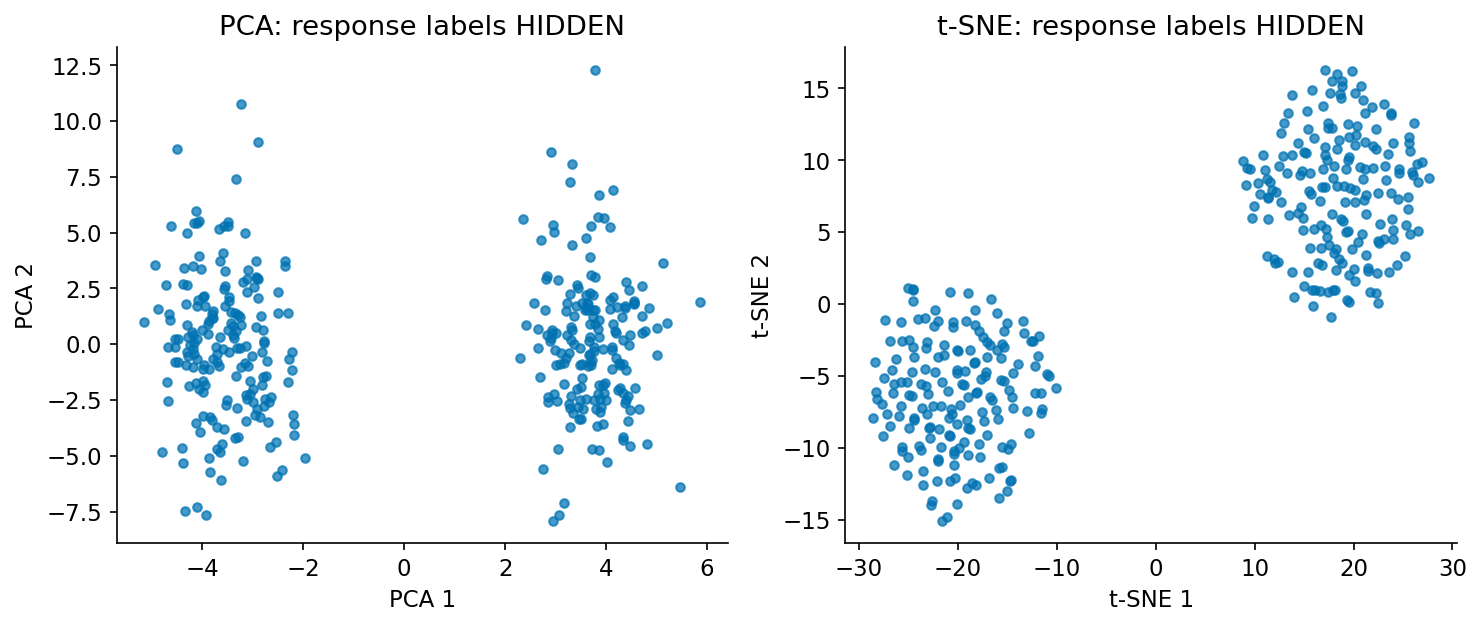

In [ ]:
visual_scaler = StandardScaler().fit(X_train)  # TRAIN only
Z_train = visual_scaler.transform(X_train)
pca_vis = PCA(n_components=2, random_state=SEED).fit(Z_train)
pc_train = pca_vis.transform(Z_train)
ts_train = TSNE(n_components=2, init='pca', learning_rate='auto',
                perplexity=30, random_state=SEED).fit_transform(Z_train)
embeddings = [('PCA',pc_train), ('t-SNE',ts_train)]
try:
    import umap
    um_train = umap.UMAP(n_components=2,n_neighbors=20,min_dist=0.12,
                         random_state=SEED).fit_transform(Z_train)
    embeddings.insert(1, ('UMAP',um_train))
except ImportError:
    print('UMAP skipped outside Colab: install umap-learn if desired.')

fig,axs=plt.subplots(1,len(embeddings),figsize=(5*len(embeddings),4.3))
axs=np.atleast_1d(axs)
for ax,(name,xy) in zip(axs,embeddings):
    ax.scatter(xy[:,0],xy[:,1],s=17,color=BLUE,alpha=.72)
    ax.set(xlabel=f'{name} 1',ylabel=f'{name} 2',title=f'{name}: response labels HIDDEN')
finish('02_unlabeled_embeddings')
print('PCA variance explained by first two PCs:',np.round(pca_vis.explained_variance_ratio_,3))

**Explain (after running, still before revealing labels):** Describe one pattern that appears in the plots. Why does it remain scientifically ambiguous until we examine relevant sample metadata?

**Your response:** The unlabeled PCA plot separates the training tumors into two conspicuous clouds along the first component, and the t-SNE plot also shows two separated collections of points. PCA components 1 and 2 explain about 17.1% and 12.2% of standardized expression variance, respectively. These pictures cannot tell us whether the clouds represent responders, tumor biology, or processing batches: the response and batch annotations have not yet been examined.

### 2a) Why projection settings matter: same tumors, different maps

Changing t-SNE `perplexity` changes the effective neighborhood scale; changing UMAP `n_neighbors` changes how much local vs broader structure shapes its layout. These parameters **do not change the underlying gene-expression matrix**. Notice which apparent islands, shapes, and gaps persist across settings. A change in the picture is not evidence that the tumors changed.

**Predict (before running):** When we change a projection's neighborhood setting, will the locations, gaps, and apparent clusters necessarily remain unchanged? Can you use the size of a t-SNE island to estimate the number of tumors it contains?

**Your response:** I predict that the positions, distances, and gap shapes will change when perplexity or n_neighbors changes, despite using exactly the same tumors and expression measurements. A t-SNE island’s apparent area is not a reliable measure of its sample count or biological frequency because the embedding distorts relative sizes and distances.

/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


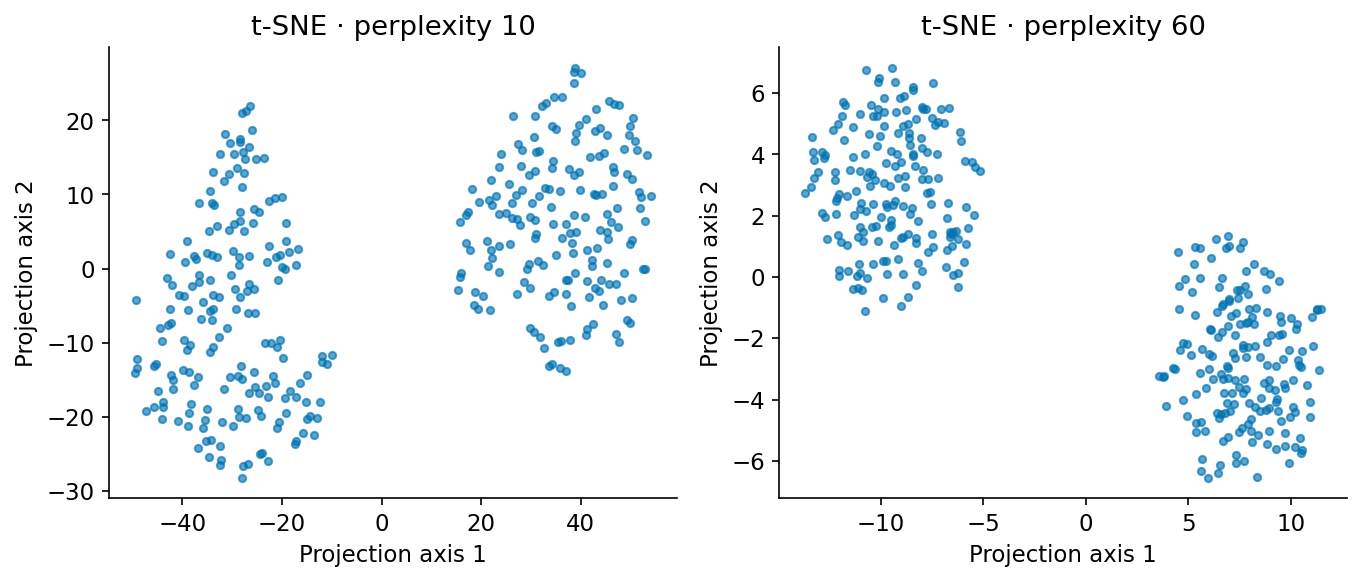

In [ ]:
# Illustrate sensitivity to two neighborhood choices; TRAIN samples only.
projections=[]
for perp in (10,60):
    xy=TSNE(n_components=2,init='pca',learning_rate='auto',
            perplexity=perp,random_state=SEED).fit_transform(Z_train)
    projections.append((f't-SNE · perplexity {perp}',xy))
try:
    import umap
    for neighbors in (8,60):
        xy=umap.UMAP(n_components=2,n_neighbors=neighbors,min_dist=.12,
                     random_state=SEED).fit_transform(Z_train)
        projections.append((f'UMAP · neighbors {neighbors}',xy))
except ImportError:
    pass
fig,axs=plt.subplots(1,len(projections),figsize=(4.6*len(projections),4.0))
for ax,(name,xy) in zip(np.atleast_1d(axs),projections):
    ax.scatter(xy[:,0],xy[:,1],s=12,alpha=.64,color=BLUE)
    ax.set(title=name,xlabel='Projection axis 1',ylabel='Projection axis 2')
finish('02_projection_settings')

**Explain (after running):** Describe one change in the *appearance* of the same tumors when a projection setting changes. Why does this make it risky to interpret every plotted island as a distinct tumor subtype? What sort of independent information would help you assess the biology?

**Your response:** Comparing t-SNE perplexity 10 versus 60, the points shift and the two populations differ in how tightly and smoothly they are arranged; their shapes and within-group spacing are not identical. The underlying tumors do not change. This sensitivity to plotting choices makes it inappropriate to define a new tumor subtype solely from an island. Independent response labels, known molecular markers, batch annotations, and replication in another cohort would help determine whether the structure is biological.

### 2b) Reveal response labels — then ask what actually drives structure **(Slide 14)**

Now color *the same training embeddings* by observed nonresponse status. We can also color PCA by simulated **technical batch**. This batch information is supplied **only for interpretation**; it is never used as a predictor.

**Predict:** Will every visible structure line up with the nonresponse label? If PCA separates batches more clearly than Nonresponders and Responders, is PCA necessarily wrong?

**Your response:** I predict that not every visible cluster will correspond to nonresponse. PCA searches for directions explaining expression variance rather than optimizing response discrimination, so a batch-related separation would not mean PCA has failed. It would mean that batch differences are a major source of the expression variance PCA was designed to capture.

/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


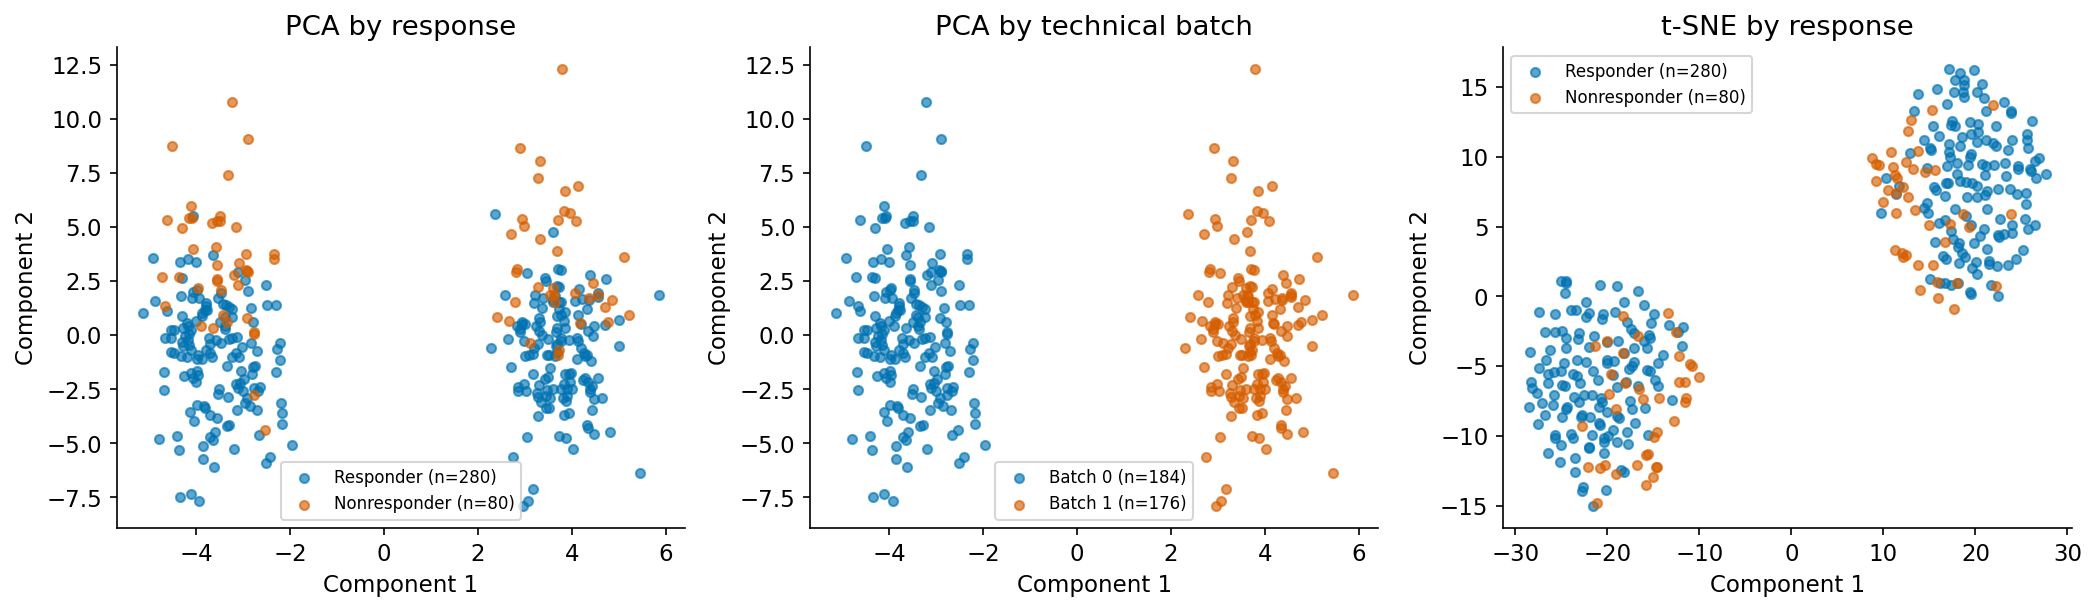

In [ ]:
plots=[('PCA by response',pc_train,y_train,('Responder','Nonresponder')),
       ('PCA by technical batch',pc_train,batch[train_idx],('Batch 0','Batch 1'))]
plots += [(f'{name} by response',xy,y_train,('Responder','Nonresponder'))
          for name,xy in embeddings if name!='PCA']
fig,axs=plt.subplots(1,len(plots),figsize=(4.7*len(plots),4.2))
axs=np.atleast_1d(axs)
for ax,(title,xy,labels,names) in zip(axs,plots):
    for lab,col in [(0,BLUE),(1,ORANGE)]:
        mask=(labels==lab)
        ax.scatter(xy[mask,0],xy[mask,1],s=19,alpha=.64,color=col,label=f'{names[lab]} (n={mask.sum()})')
    ax.legend(fontsize=8)
    ax.set(xlabel='Component 1',ylabel='Component 2',title=title)
finish('02_metadata_reveal')

**Explain:** Which metadata variable appears more closely related to the main PCA structure: **response class** or **technical batch**? How does this connect to our earlier question about whether unsupervised clusters represent biologically meaningful subtypes? Can a supervised classifier still extract nonresponse-related signal that is *not* the dominant source of variance?

**Your response:** Technical batch aligns much more closely with the main PCA split than response class does. Coloring by batch reveals two mostly distinct groups, whereas coloring by response shows overlap within those groups. Therefore, the unlabeled islands did not establish two meaningful treatment-response subtypes. A supervised classifier can still use subtler combinations of expression features associated with nonresponse, even if those features do not explain the largest overall variance.

## 3) Classifier family 1: Logistic Regression **(Slides 15-18)**

Despite the name, **logistic regression is a classifier**. For a binary response, it computes a *linear score* from expression features, then converts that score to a predicted probability using the sigmoid:

$$ z = b + \sum_j w_j x_j, \qquad P(\mathrm{Nonresponder}\mid X)=\frac{1}{1+e^{-z}}. $$

A **decision threshold**, often `0.50`, converts that score into a Nonresponder (1) / Responder (0) prediction. The `C` hyperparameter is the **inverse strength of regularization**: smaller `C` means stronger regularization. Here, as in lecture, we can visualize a 2-gene model; the full predictor later uses all 80 genes.

**Predict:** If `P(nonresponse) = 0.41`, which class will be predicted with threshold `0.50`? With threshold `0.25`? If we increase `Gene_01` and its coefficient is positive, which direction does predicted probability of nonresponse move?

**Your response:** At threshold 0.50, a predicted nonresponse probability of 0.41 is classified as Responder (0); at threshold 0.25, the same tumor is classified as Nonresponder (1). If Gene_01 has a positive fitted coefficient, increasing its standardized expression while holding other inputs fixed should increase the score, odds, and predicted probability of nonresponse.

Intercept: -1.621   Standardized gene coefficients: {'Gene_01': np.float64(0.713), 'Gene_16': np.float64(-1.022)}


/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


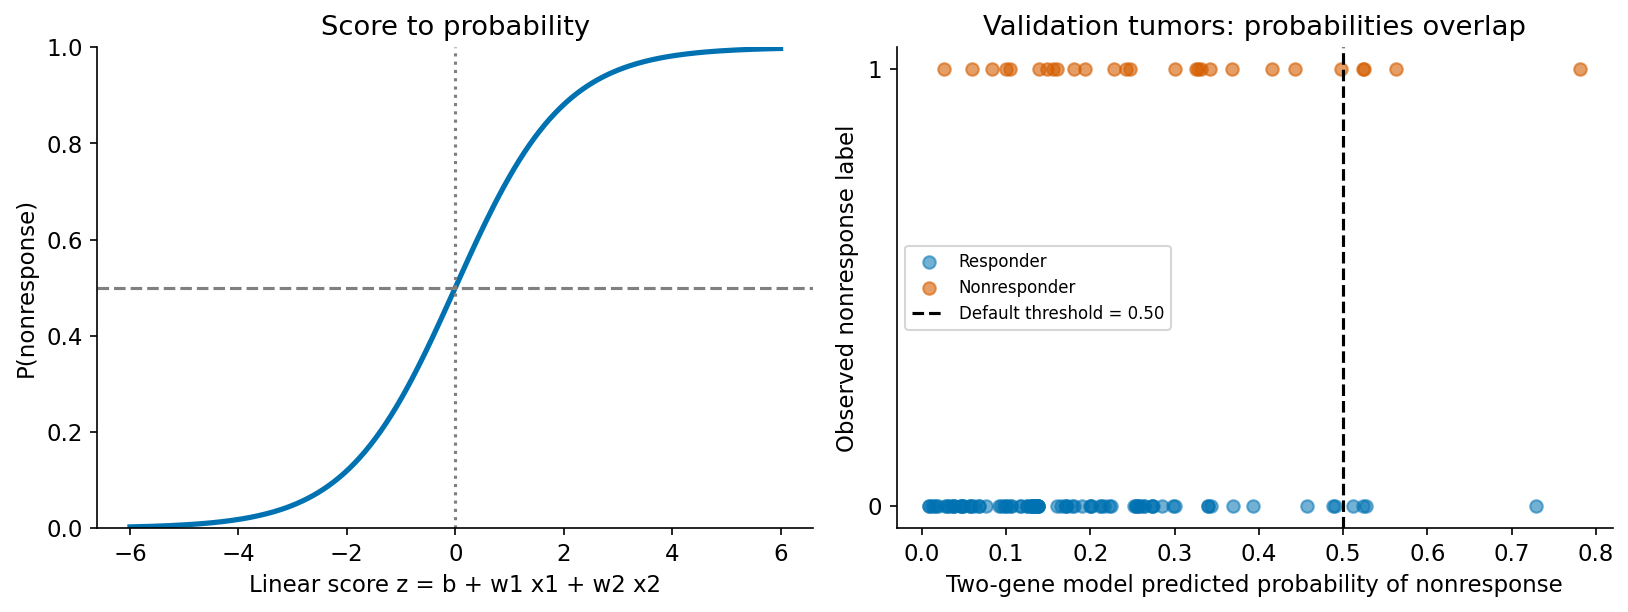

In [ ]:
TWO = [0,15]   # Gene_01 and Gene_16 (one from each latent expression program)
X2_tr, X2_val = X_train[:,TWO], X_val[:,TWO]
logit2 = make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000))
logit2.fit(X2_tr,y_train)
b=float(logit2.named_steps['logisticregression'].intercept_[0])
w=logit2.named_steps['logisticregression'].coef_[0]
z=np.linspace(-6,6,250)
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
axs[0].plot(z,expit(z),color=BLUE,linewidth=2.5)
axs[0].axhline(.5,color='gray',linestyle='--'); axs[0].axvline(0,color='gray',linestyle=':')
axs[0].set(xlabel='Linear score z = b + w1 x1 + w2 x2', ylabel='P(nonresponse)',title='Score to probability',ylim=(0,1))
p2=logit2.predict_proba(X2_val)[:,1]
axs[1].scatter(p2[y_val==0],np.zeros((y_val==0).sum()),color=BLUE,alpha=.55,label='Responder')
axs[1].scatter(p2[y_val==1],np.ones((y_val==1).sum()),color=ORANGE,alpha=.60,label='Nonresponder')
axs[1].axvline(.5,color='black',ls='--',label='Default threshold = 0.50')
axs[1].set(xlabel='Two-gene model predicted probability of nonresponse',ylabel='Observed nonresponse label',yticks=[0,1],title='Validation tumors: probabilities overlap')
axs[1].legend(fontsize=8)
finish('03_logistic_probabilities')
print('Intercept:',round(b,3),'  Standardized gene coefficients:',dict(zip([GENES[j] for j in TWO],np.round(w,3))))

**Explain:** Read the fitted coefficients in the output. Which of these genes increases predicted nonresponse *odds*, holding the other fixed? Are these coefficients causal effects? Why can predicted probabilities overlap even when the classifier has learned a useful signal?

**Your response:** The fitted standardized coefficient for Gene_01 is +0.713 and for Gene_16 is −1.022 (intercept −1.621). Holding the other gene fixed, higher Gene_01 expression raises the estimated log-odds of nonresponse, whereas higher Gene_16 expression lowers them. These are conditional predictive associations, not evidence that experimentally altering either gene changes treatment response. The probabilities overlap because expression varies within both outcome groups and two genes cannot perfectly explain a probabilistic outcome.

# Changing the threshold does not retrain the classifier **(Slide 19)**

**Predict:** Before moving the threshold from 0.50 to 0.20, predict what will happen to sensitivity, specificity, and the number of false positives.

**Explain:** Move the slider and examine the results. Why do the confusion matrix and performance metrics change even though the logistic regression model has not been retrained? Does lowering the threshold necessarily decrease precision?

**Response:** **Prediction (recorded before comparing thresholds):** Lowering the cutoff from 0.50 to 0.20 should increase sensitivity, reduce specificity, and create more false positives as more tumors are labeled Nonresponders.

**Observed and explanation:** In the two-gene logistic model, at 0.50 the validation counts were TN=89, FP=4, FN=23, TP=4. At 0.20 they were TN=60, FP=33, FN=11, TP=16. Sensitivity therefore rose from 4/27=0.148 to 16/27=0.593, while specificity fell from 89/93=0.957 to 60/93=0.645. The model and its probabilities did not change; only the mapping from probabilities to class labels changed. Precision need not decrease mathematically with every threshold reduction, since newly included cases may contain a greater fraction of true positives; here it fell from 4/8=0.500 to 16/49=0.327.

ipywidgets unavailable locally; showing fixed threshold 0.50 and 0.20 outputs. Interactive slider works in Colab.


/tmp/ipykernel_637/2291136614.py:77: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Accuracy,Sensitivity,Specificity,Precision,F1
0,0.775,0.148,0.957,0.5,0.229


TN=89   FP=4   FN=23   TP=4
Model coefficients and predicted probabilities are unchanged.


/tmp/ipykernel_637/2291136614.py:77: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Accuracy,Sensitivity,Specificity,Precision,F1
0,0.633,0.593,0.645,0.327,0.421


TN=60   FP=33   FN=11   TP=16
Model coefficients and predicted probabilities are unchanged.


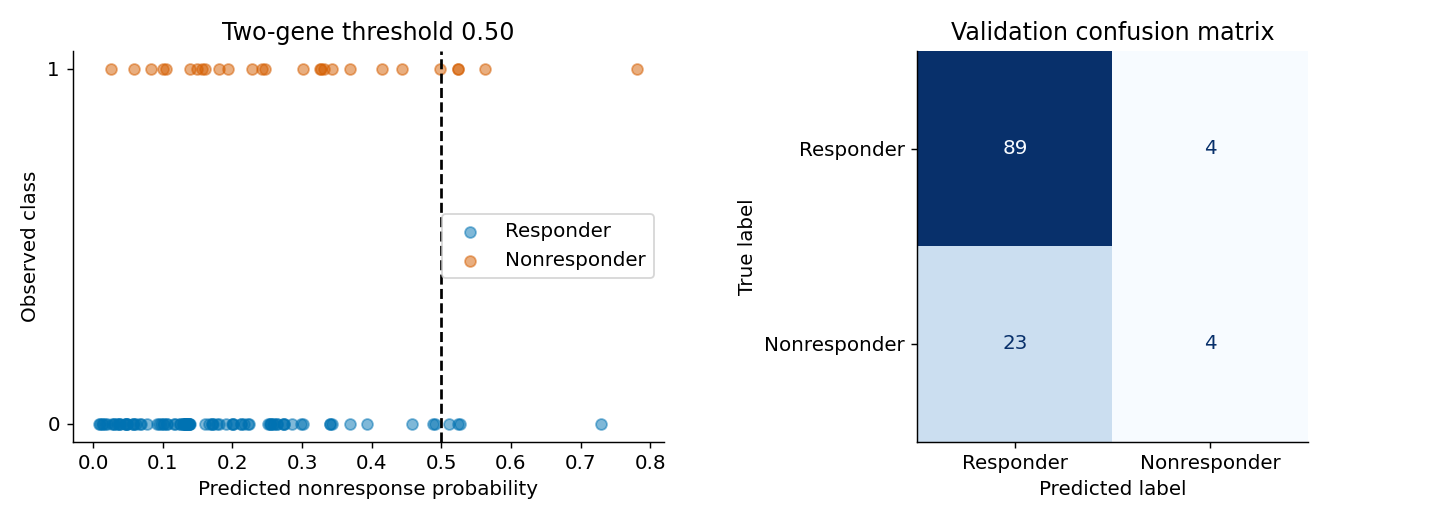

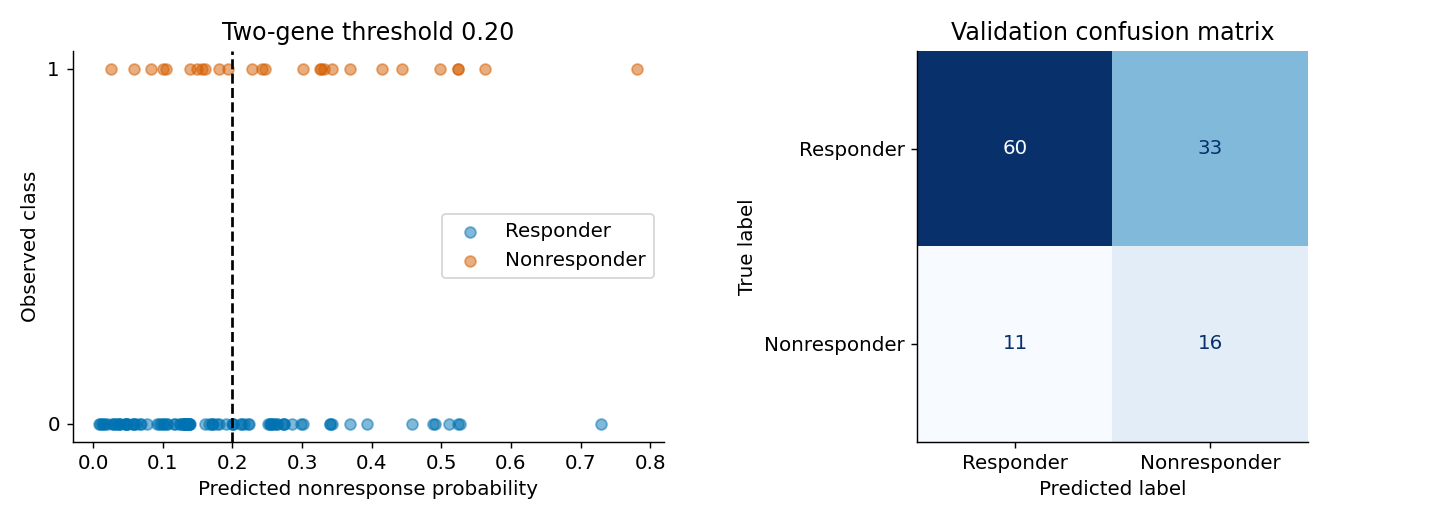

In [ ]:
try:
    import ipywidgets as widgets
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    class _FallbackWidgets:
        @staticmethod
        def FloatSlider(**kwargs): return kwargs
        @staticmethod
        def interact(**kwargs):
            def decorator(func):
                for t in [0.50, 0.20]:
                    func(t)
                return func
            return decorator
    widgets = _FallbackWidgets()
    print('ipywidgets unavailable locally; showing fixed threshold 0.50 and 0.20 outputs. Interactive slider works in Colab.')

# Fixed validation probabilities from the trained logistic regression
# p2 was calculated in the preceding cell.
jitter = np.random.default_rng(42).normal(0, 0.04, len(y_val))

@widgets.interact(
    threshold=widgets.FloatSlider(
        value=0.50, min=0.05, max=0.95, step=0.05,
        description="Threshold:",
        continuous_update=False
    )
)
def explore_threshold(threshold):

    # Change classifications WITHOUT retraining the model
    predictions = (p2 >= threshold).astype(int)
    m = metrics(y_val, predictions)

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

    # LEFT: Predicted probabilities for each tumor
    for actual, label, color in [
        (0, "Actual Responder", BLUE),
        (1, "Actual Nonresponder", ORANGE)
    ]:
        mask = y_val == actual
        axs[0].scatter(
            p2[mask], y_val[mask] + jitter[mask],
            color=color, alpha=0.65, s=35, label=label
        )

    # Highlight incorrectly classified tumors
    wrong = predictions != y_val
    axs[0].scatter(
        p2[wrong], y_val[wrong] + jitter[wrong],
        marker="x", color="black", s=65,
        label="Incorrect prediction"
    )

    # Decision threshold
    axs[0].axvline(threshold, color="black", linestyle="--",
                   linewidth=2, label=f"Threshold = {threshold:.2f}")

    axs[0].set(
        xlabel="Predicted probability of Nonresponse",
        ylabel="Actual treatment response",
        yticks=[0, 1],
        yticklabels=["Responder", "Nonresponder"],
        xlim=(0, 1),
        ylim=(-0.2, 1.2),
        title="Same probabilities, different classifications"
    )
    axs[0].legend(fontsize=8, loc="upper center")

    # RIGHT: Updated confusion matrix
    show_cm(axs[1], y_val, predictions,
            f"Confusion matrix (threshold = {threshold:.2f})")

    plt.tight_layout()
    plt.show()

    # Updated performance metrics
    display(pd.DataFrame([{
        "Accuracy": m["accuracy"],
        "Sensitivity": m["sensitivity / recall"],
        "Specificity": m["specificity"],
        "Precision": m["precision"],
        "F1": m["F1"]
    }]).round(3))

    print(f"TN={m['TN']}   FP={m['FP']}   FN={m['FN']}   TP={m['TP']}")
    print("Model coefficients and predicted probabilities are unchanged.")

## 4) Classifier family 2: Support Vector Machine (SVM) **(Slides 20-22)**

An **SVM** tries to separate labeled classes by a decision boundary with a large margin. A Radial Basis Function (RBF) kernel permits **nonlinear boundaries** without explicitly constructing all transformed coordinates.

The two hyperparameters emphasized in lecture are:

- **`C`**: how strongly to penalize classification errors. Small `C` = more regularization; large `C` = stronger pressure to fit training labels.
- **`gamma`**: how local a training point's influence is in the **RBF kernel**. Small `gamma` = smoother, broad influence; large `gamma` = narrower, more flexible influence.

Below we show Logistic Regression, RBF SVM, and Random Forest **using the same two genes**. These 2D diagrams explain shapes, **not** final 80-gene model selection.

**Predict:** Which family should have a *straight* decision boundary? Which can bend around individual groups? Will increasing `gamma` and `C` always improve predictions on **validation** samples?

**Your response:** Logistic regression should yield a straight decision boundary in the two-gene plane. RBF SVM and Random Forest can form nonlinear and irregular boundaries around groups of points. Increasing both gamma and C can make an SVM follow individual training observations more closely, but I do not expect it always to improve validation performance because greater flexibility can overfit noise.

/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Classifier,TRAIN F1,VALIDATION F1
0,Logistic regression,0.411,0.229
1,"RBF SVM (C=1, gamma=scale)",0.355,0.129
2,Random forest,0.641,0.167


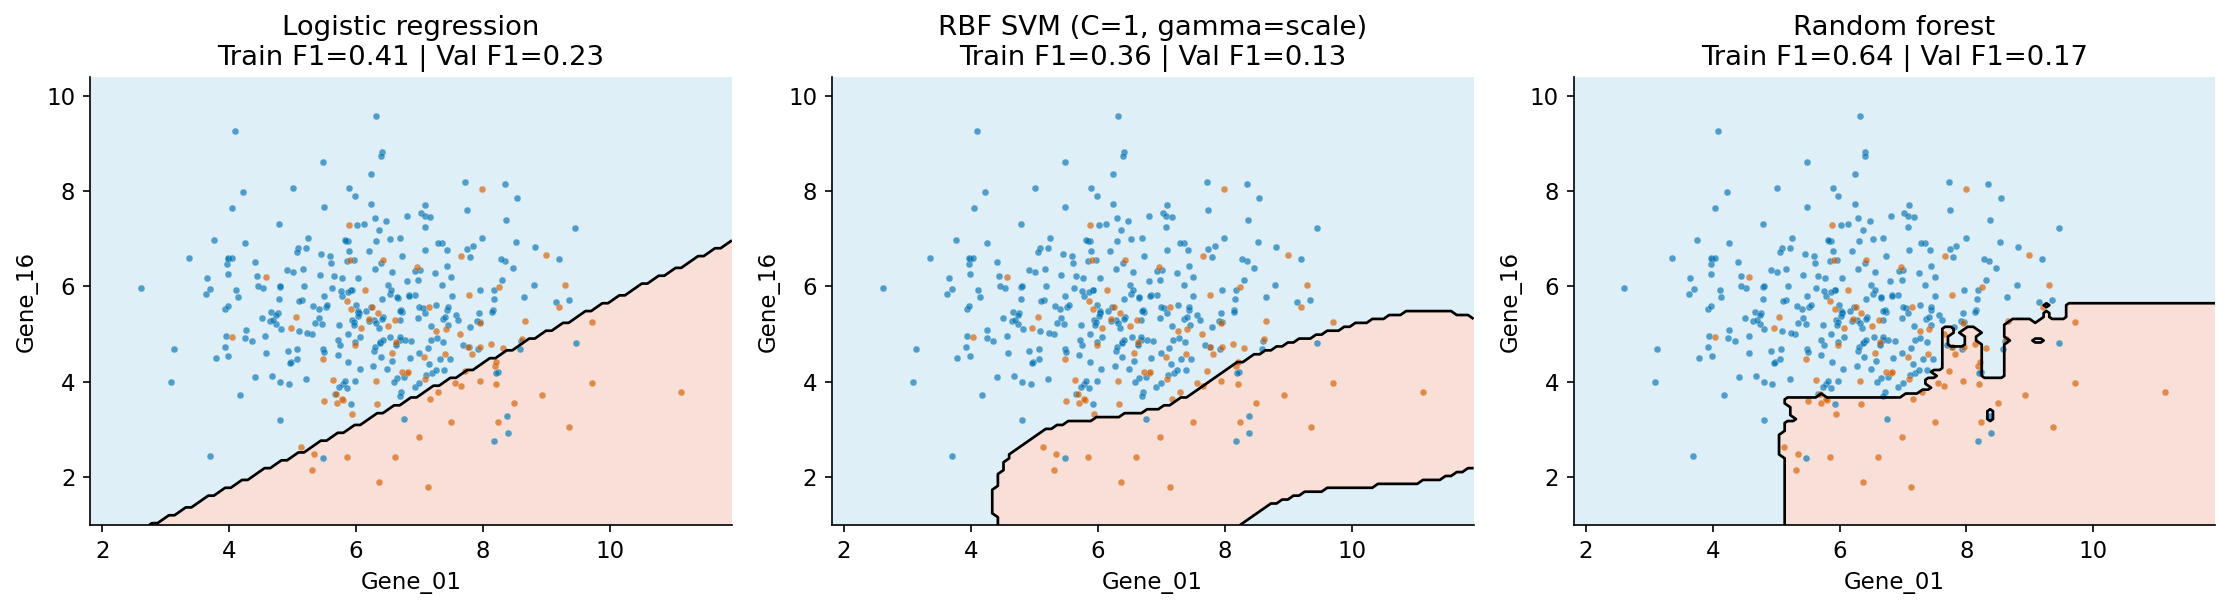

In [ ]:
from matplotlib.colors import ListedColormap

def boundary_panel(ax,model,name):
    model.fit(X2_tr,y_train)
    margin=0.8
    x1=np.linspace(X2_tr[:,0].min()-margin,X2_tr[:,0].max()+margin,115)
    x2=np.linspace(X2_tr[:,1].min()-margin,X2_tr[:,1].max()+margin,115)
    xx,yy=np.meshgrid(x1,x2)
    xy=np.c_[xx.ravel(),yy.ravel()]
    classes=model.predict(xy).reshape(xx.shape)
    ax.contourf(xx,yy,classes,levels=[-.5,.5,1.5],colors=['#D8EBF7','#F7D8CD'],alpha=.8)
    ax.contour(xx,yy,classes,levels=[.5],colors='black',linewidths=1.3)
    for cls,color in [(0,BLUE),(1,ORANGE)]:
        mask=y_train==cls
        ax.scatter(X2_tr[mask,0],X2_tr[mask,1],s=11,alpha=.65,
                   c=color,edgecolors='white',linewidths=.15)
    tr_f1=f1_score(y_train,model.predict(X2_tr),zero_division=0)
    vl_f1=f1_score(y_val,model.predict(X2_val),zero_division=0)
    ax.set(xlabel='Gene_01',ylabel='Gene_16',title=f'{name}\nTrain F1={tr_f1:.2f} | Val F1={vl_f1:.2f}')
    return tr_f1,vl_f1

boundaries={
 'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),
 'RBF SVM (C=1, gamma=scale)':make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1,gamma='scale',probability=True,random_state=SEED)),
 'Random forest':RandomForestClassifier(n_estimators=100,max_depth=6,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
}
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
boundary_results=[]
for ax,(name,model) in zip(axs,boundaries.items()):
    train_f1,val_f1=boundary_panel(ax,model,name)
    boundary_results.append((name,train_f1,val_f1))
finish('04_three_classifier_boundaries')
display(pd.DataFrame(boundary_results,columns=['Classifier','TRAIN F1','VALIDATION F1']).round(3))

### 4a) Experiment with `C` and `gamma`
Compare **four RBF SVM settings** with the same training/validation data. The dotted question from lecture is: *when does extra flexibility turn into overfitting?*

**Predict:** Between `C=0.1, gamma=0.03` and `C=50, gamma=5`, which is more likely to fit isolated training observations? Which will necessarily have the better validation F1?

**Your response:** I predict C=50, gamma=5 will be more likely to follow isolated training observations than C=0.1, gamma=0.03. It is not possible to guarantee which will have higher validation F1 from hyperparameters alone; that depends on the held-out sample patterns. The very flexible model might achieve higher training F1 but generalize worse.

/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,C,gamma,TRAIN F1,VALIDATION F1
0,0.1,0.03,0.000,0.000
1,50.0,0.03,0.300,0.133
2,0.1,5.00,0.000,0.000
3,50.0,5.00,0.708,0.263


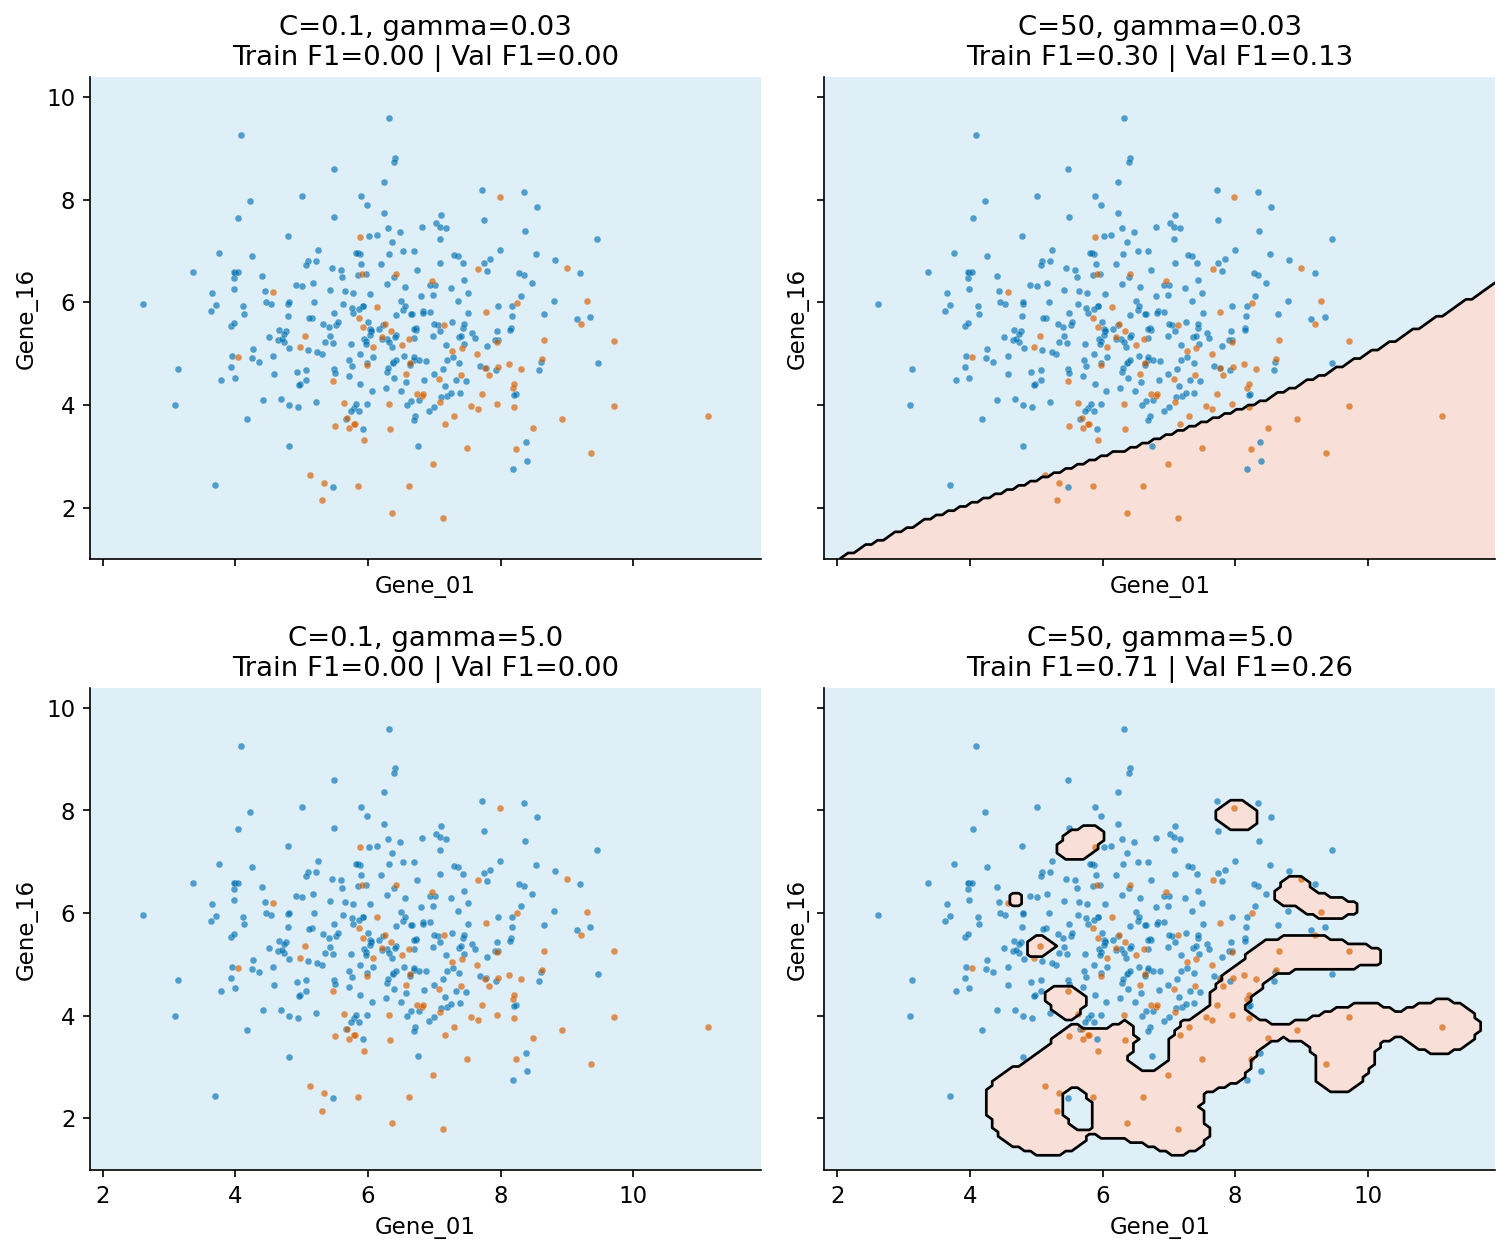

In [ ]:
# C and gamma are hyperparameters supplied before training, NOT learned coefficients.
settings=[(.1,.03), (50,.03), (.1,5.0), (50,5.0)]
fig,axs=plt.subplots(2,2,figsize=(10.2,8.5),sharex=True,sharey=True)
rows=[]
for ax,(C,gamma) in zip(axs.flat,settings):
    model=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=C,gamma=gamma,
                       probability=True,random_state=SEED))
    tr,vl=boundary_panel(ax,model,f'C={C}, gamma={gamma}')
    rows.append({'C':C,'gamma':gamma,'TRAIN F1':tr,'VALIDATION F1':vl})
finish('04_svm_c_gamma')
display(pd.DataFrame(rows).round(3))

**Explain:** Point to the panel with the most flexible/complex boundary. Does its training F1 look like a reliable estimate of generalization? Explain one visible instance in which allowing more complex decision boundaries helps or hurts validation performance.

**Your response:** The C=50, gamma=5 panel shows the most locally flexible, irregular boundary. Its training F1 was 0.708, but validation F1 was only 0.263, so the training result alone substantially overstates performance on unseen tumors. In contrast, C=50, gamma=0.03 produced training F1=0.300 and validation F1=0.133, while the heavily regularized C=0.1 settings classified essentially no positives (both training and validation F1=0). Here increasing flexibility helps the validation F1 relative to those settings, yet leaves a large train–validation gap that indicates poor generalization.

## 5) Classifier family 3: Random Forest **(Slides 23-25)**

A **Random Forest** aggregates many decision trees. Each tree uses a **bootstrap sample** of the training observations and considers a random subset of features at a split. Its class probability is typically the **average class probability from the trees**, so it can also be thresholded.

The *impurity-based feature importance* scores (Gini index) indicate which features the trees used to reduce impurity, **not** proof of biological causation. Correlated expression measurements may split importance among themselves.

#### Visualize the first few layers of the first tree in the Random Forest

/tmp/ipykernel_637/3263890749.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


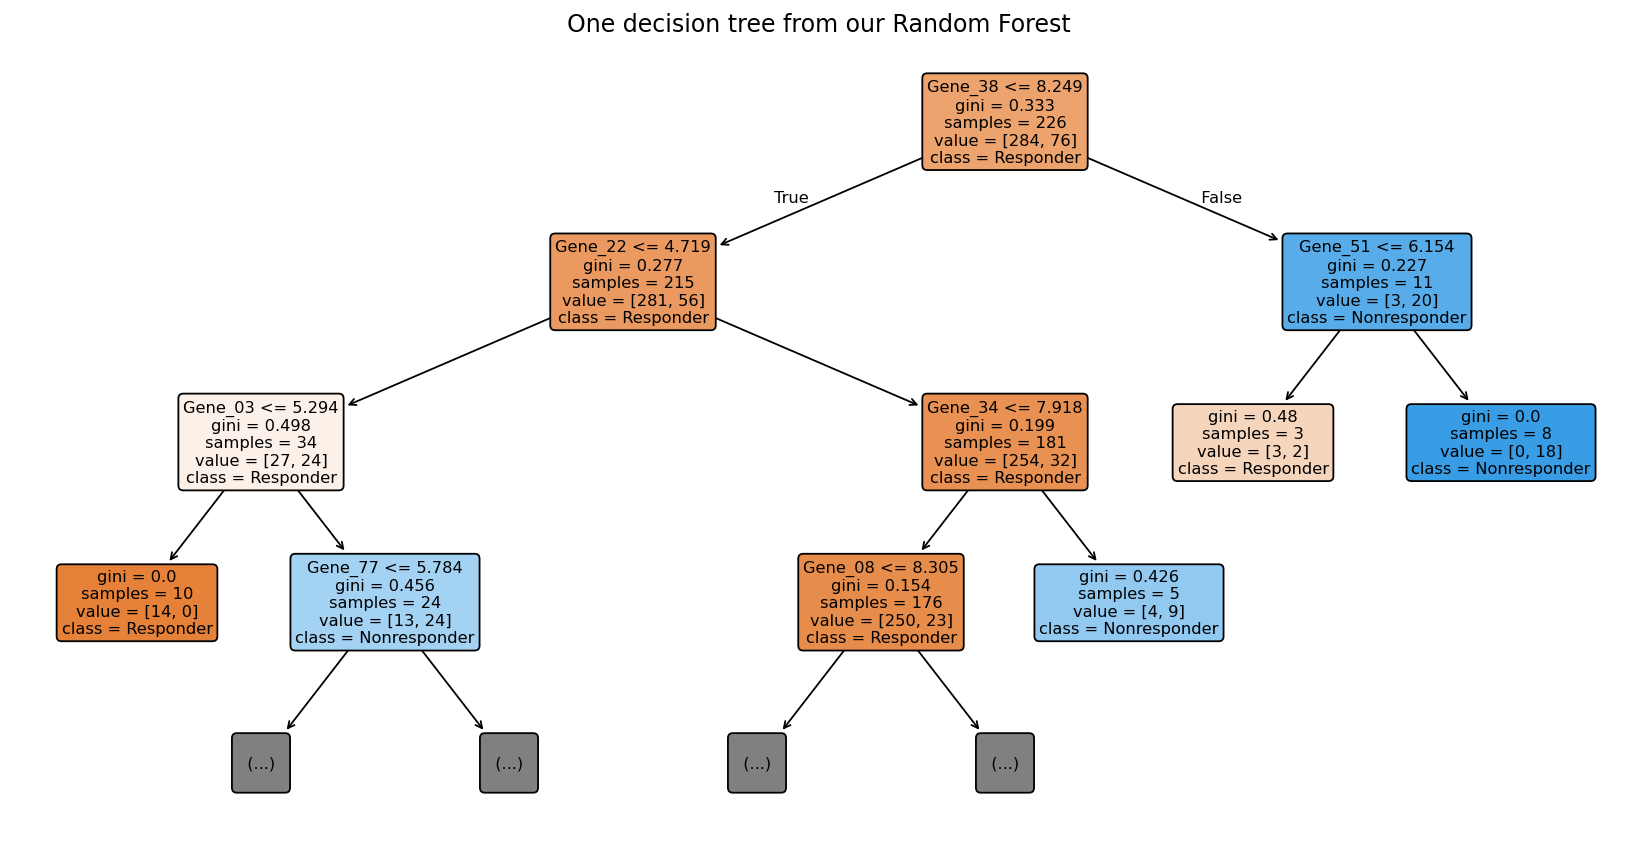

In [ ]:
from sklearn.tree import plot_tree

rf_demo=RandomForestClassifier(n_estimators=150,max_depth=7,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
rf_demo.fit(X_train,y_train)

plt.figure(figsize=(16, 8))

plot_tree(
    rf_demo.estimators_[0],
    feature_names=GENES,
    class_names=["Responder", "Nonresponder"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("One decision tree from our Random Forest")
plt.savefig(OUT / '05_random_forest_tree.png', dpi=150, bbox_inches='tight')
plt.show()

**Predict:** Why might a Random Forest perform better on new samples than a single unpruned decision tree?

**Explain:** Run the cell below and examine the Random Forest feature-importance plot. Which genes contribute most to classification? Does high feature importance demonstrate that these genes cause treatment nonresponse? Why or why not?

**Your response:** **Prediction:** A Random Forest should usually be less unstable than a single unpruned decision tree because averaging predictions from many bootstrapped, feature-randomized trees reduces the influence of any one unusual training sample.

**Observed and explanation:** The feature-importance plot ranks Gene_12, Gene_06, Gene_27, Gene_13, and Gene_16 among the largest contributors. Several are in the simulated latent-program gene ranges, which is consistent with the data-generating mechanism. However, impurity importance measures how often and how effectively features improve tree splits; correlated features and chance structure can affect those rankings. High importance does not show that a gene causes resistance. The demonstration forest also had training F1=0.904 versus validation F1=0.432, illustrating overfitting even with an ensemble.

Random Forest training F1: 0.904
Random Forest validation F1: 0.432


/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


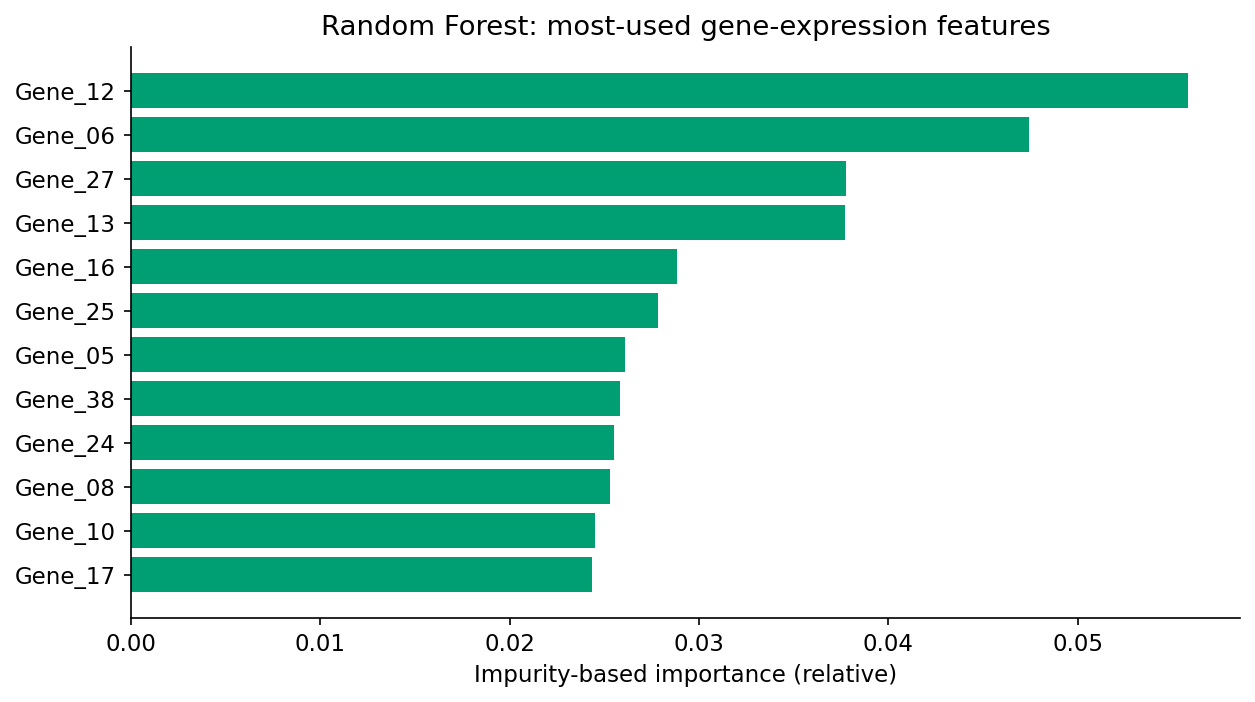

In [ ]:
important=np.argsort(rf_demo.feature_importances_)[-12:][::-1]
fig,ax=plt.subplots(figsize=(8.5,4.8))
ax.barh([GENES[i] for i in important[::-1]],rf_demo.feature_importances_[important[::-1]],color=GREEN)
ax.set(xlabel='Impurity-based importance (relative)',title='Random Forest: most-used gene-expression features')
finish('05_random_forest_features')
print('Random Forest training F1:',round(f1_score(y_train,rf_demo.predict(X_train)),3))
print('Random Forest validation F1:',round(f1_score(y_val,rf_demo.predict(X_val)),3))

---
# **Lecture 2 · Training, Tuning, and Evaluating Classifiers**

**Checkpoint:** You have seen how three classifier families produce predictions. Now ask whether those predictions are reliable on *new tumors*. In Lecture 2 we choose hyperparameters with training-only cross-validation, choose a decision threshold with validation data, and assess the frozen model once on the test set.

**Recall:** Positive class = **Nonresponder (1)**; **sensitivity** = TP / (TP + FN) for nonresponders.

## 6) Leakage-safe Pipelines, cross-validation and grid search

This section follows the workflow from lecture:

1. Keep the **held-out TEST** samples completely untouched.
2. On the **TRAIN** samples, a scikit-learn **Pipeline** fits preprocessing inside each cross-validation training fold, then learns a classifier.
3. **StratifiedKFold** keeps the positive/negative proportions approximately balanced across folds.
4. **GridSearchCV** evaluates predefined hyperparameter combinations and selects the best **cross-validation** score; we compare the three families.
5. The chosen model is evaluated on **VALIDATION** data to choose an operating threshold; only then do we use the TEST samples **once**.

Why `scoring='average_precision'` instead of just accuracy? In this example, the nonresponse class is less common and **ranking true nonresponders above responder tumors** matters. Average precision summarizes the precision–recall curve, **without fixing a 0.50 threshold**. We will also report ROC-AUC and classification counts.

**Predict:** What leakage occurs if you standardize **all** samples *before splitting*, or use test-set F1 to decide which `C` and `gamma` to use? Is `C` a model parameter or hyperparameter?

**Your response:** I predict leakage would occur if the scaler learned means and variances from all 600 samples before splitting, because the held-out samples would influence the transformation applied during model fitting. Using TEST F1 to select C or gamma would be more direct leakage: the supposed final independent evaluation would become part of model selection. Scaling therefore belongs inside TRAIN cross-validation folds, the threshold is selected from VALIDATION, and TEST is held back until the decisions are fixed. C is a hyperparameter chosen before fitting, not a learned coefficient.

In [ ]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
models={
 'Logistic regression':Pipeline([('scale',StandardScaler()),
                                  ('clf',LogisticRegression(max_iter=2500,random_state=SEED))]),
 'RBF SVM':Pipeline([('scale',StandardScaler()),
                      ('clf',SVC(kernel='rbf',probability=True,random_state=SEED))]),
 'Random Forest':Pipeline([('clf',RandomForestClassifier(random_state=SEED,n_jobs=1))])
}
parameter_grids={
 'Logistic regression':{'clf__C':[.1,1,10]},
 'RBF SVM':{'clf__C':[.1,1,10],'clf__gamma':[.001,'scale',.1]},
 'Random Forest':{'clf__n_estimators':[100,200],'clf__min_samples_leaf':[2,6]}
}

searches={}; cv_rows=[]
for name,pipe in models.items():
    grid=GridSearchCV(pipe,parameter_grids[name],scoring='average_precision',
                      cv=cv,n_jobs=1,refit=True)
    grid.fit(X_train,y_train) # scaler is fitted anew *inside each fold*.
    searches[name]=grid
    cv_rows.append({'Classifier':name,'Mean CV AP':grid.best_score_,
                    'Best hyperparameters':str(grid.best_params_)})
cv_table=pd.DataFrame(cv_rows).sort_values('Mean CV AP',ascending=False).reset_index(drop=True)
display(cv_table.round(3))
chosen_name=cv_table.iloc[0]['Classifier']
chosen_model=searches[chosen_name].best_estimator_
print('Selected by TRAIN-only cross-validated average precision:',chosen_name)
print('Training-only fitted model:',chosen_model)
cv_table.to_csv(OUT/'cv_model_selection.csv',index=False)

,Classifier,Mean CV AP,Best hyperparameters
0,RBF SVM,0.792,"{'clf__C': 0.1, 'clf__gamma': 0.001}"
1,Random Forest,0.742,"{'clf__min_samples_leaf': 6, 'clf__n_estimator..."
2,Logistic regression,0.704,{'clf__C': 0.1}


Selected by TRAIN-only cross-validated average precision: RBF SVM
Training-only fitted model: Pipeline(steps=[('scale', StandardScaler()),
                ('clf',
                 SVC(C=0.1, gamma=0.001, probability=True, random_state=42))])


### 6a) Visualize the SVM grid search

A grid is an explicit, finite search over `C × gamma`. The grid uses gamma = 0.001, `scale`, and 0.1. The `scale` setting automatically computes gamma = 1 / (number of features × variance); with 80 standardized expression features, it is approximately **0.0125**.

Colors below show **mean cross-validated average precision on training folds**; these scores are *not* test performance. A setting is not guaranteed to be optimal just because it wins a small grid.

**Predict:** If the same data are reused to test hundreds of hyperparameter combinations, why might even the best cross-validation score be optimistic? What should remain untouched?

**Your response:** Searching more configurations increases the opportunity to select an unusually high cross-validation score simply because of sampling noise, making the winning score somewhat optimistic. I predict performance on independent data may be lower. The TEST set should remain completely untouched by parameter search, model-family choice, and threshold selection; this is why the notebook uses training-only CV and a separate validation threshold.

/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


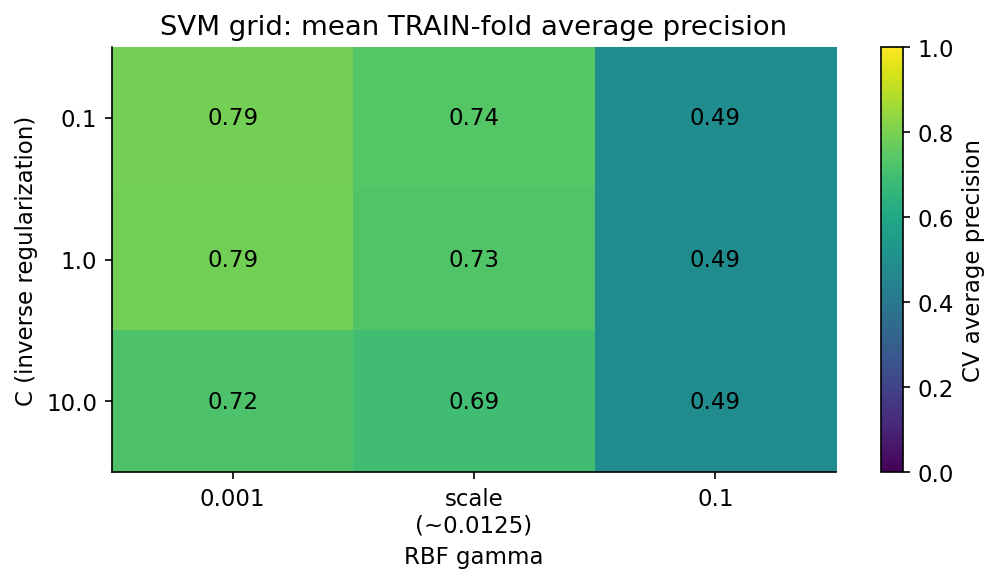

In [ ]:
svm_cv=pd.DataFrame(searches['RBF SVM'].cv_results_)
svm_cv['C']=svm_cv['param_clf__C'].astype(float)
svm_cv['gamma']=svm_cv['param_clf__gamma'].astype(str)
pivot=(svm_cv.pivot(index='C',columns='gamma',values='mean_test_score')
       .reindex(columns=['0.001','scale','0.1']))
fig,ax=plt.subplots(figsize=(7.0,4.0))
im=ax.imshow(pivot.to_numpy(),cmap='viridis',aspect='auto',vmin=0,vmax=1)
# 'scale' is approximately 1 / 80 = 0.0125 after StandardScaler.
ax.set_xticks(range(len(pivot.columns)),['0.001','scale\n(~0.0125)','0.1'])
ax.set_yticks(range(len(pivot.index)),pivot.index)
ax.set(xlabel='RBF gamma',ylabel='C (inverse regularization)',
       title='SVM grid: mean TRAIN-fold average precision')
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val=pivot.iloc[i,j]
        ax.text(j,i,f'{val:.2f}',ha='center',va='center',
                color='white' if val<.48 else 'black',fontsize=11)
fig.colorbar(im,ax=ax,label='CV average precision')
finish('06_svm_grid_search')

**Explain:** Which SVM `C`/`gamma` setting achieved the highest mean CV average precision? Which model family won overall? Does that prove the same ranking must hold for a new population or a future laboratory?

**Your response:** The best RBF SVM setting was C=0.1 and gamma=0.001, with mean five-fold TRAIN cross-validation average precision approximately 0.792. It also won the comparison of model families: Random Forest achieved about 0.742 and Logistic Regression about 0.704. This ranking reflects these particular simulated tumors, candidate grids, and cross-validation folds; changes in populations, batch effects, prevalence, or laboratory measurement could change which classifier performs best.

## 7) Classification errors: sensitivity, specificity, precision and F1

From this point forward, evaluate the cross-validation-selected classifier on the **VALIDATION** samples only. **Nonresponder = positive** (`1`).

| | Predicted Responder (`0`) | Predicted Nonresponder (`1`) |
|---|---:|---:|
| **Actually Responder (`0`)** | **TN** = true negative | **FP** = false positive (false alarm) |
| **Actually Nonresponder (`1`)** | **FN** = false negative (missed nonresponse) | **TP** = true positive |

\[ \mathrm{Sensitivity/Recall}=\frac{TP}{TP+FN},\qquad \mathrm{Specificity}=\frac{TN}{TN+FP} \]
\[ \mathrm{Precision}=\frac{TP}{TP+FP},\qquad F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}. \]

A nonresponder incorrectly predicted responder (**FN**) could receive ineffective treatment if this were a legitimate clinical tool. A responder tumor incorrectly predicted nonresponse (**FP**) could be denied an effective treatment. **Neither error has a universal cost**. F1 is a teaching objective here, not a clinical recommendation.

**Predict:** If we **lower** the threshold from `0.50` to `0.20`, will sensitivity tend to rise or fall? What happens to the number of false positives? Must *precision* decrease in every possible dataset?

**Your response:** I predict a lower threshold will identify more actual Nonresponders, so sensitivity will rise or stay the same, but more actual Responders are likely to be flagged, increasing false positives. Precision need not decrease every time the threshold is lowered; that depends on the actual labels of newly flagged samples.

,threshold,accuracy,balanced_accuracy,sensitivity / recall,specificity,precision,F1,TN,FP,FN,TP
0,0.20,0.767,0.771,0.778,0.763,0.488,0.600,71,22,6,21
1,0.35,0.783,0.742,0.667,0.817,0.514,0.581,76,17,9,18
2,0.50,0.800,0.726,0.593,0.860,0.552,0.571,80,13,11,16
3,0.65,0.783,0.650,0.407,0.892,0.524,0.458,83,10,16,11
4,0.80,0.817,0.632,0.296,0.968,0.727,0.421,90,3,19,8


Always-Responder validation baseline: {'accuracy': 0.775, 'balanced_accuracy': 0.5, 'sensitivity / recall': 0.0, 'specificity': np.float64(1.0), 'precision': 0.0, 'F1': 0.0, 'TN': 93, 'FP': 0, 'FN': 27, 'TP': 0}


/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


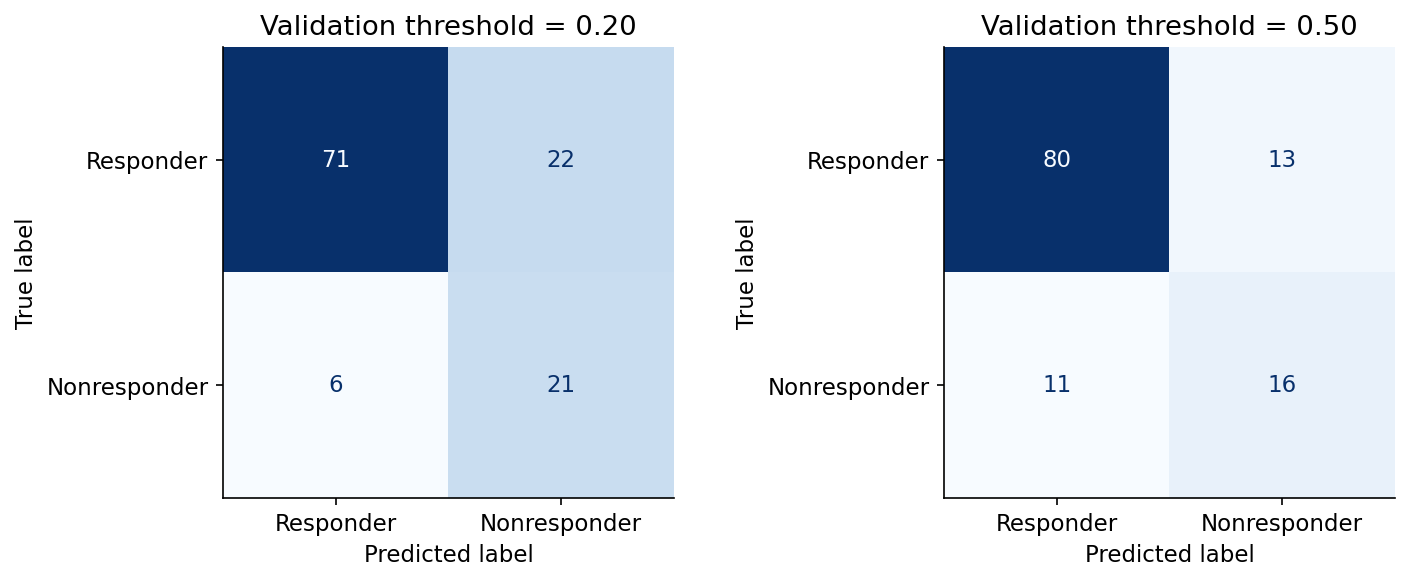

In [ ]:
val_prob=chosen_model.predict_proba(X_val)[:,1]
THRESHOLDS=[.20,.35,.50,.65,.80]
metrics_by_threshold=pd.DataFrame([
    {'threshold':t,**metrics(y_val,(val_prob>=t).astype(int))}
    for t in THRESHOLDS])
display(metrics_by_threshold.round(3))

fig,axs=plt.subplots(1,2,figsize=(10,4))
show_cm(axs[0],y_val,(val_prob>=.20).astype(int),'Validation threshold = 0.20')
show_cm(axs[1],y_val,(val_prob>=.50).astype(int),'Validation threshold = 0.50')
finish('07_confusion_matrices')

print('Always-Responder validation baseline:',metrics(y_val,np.zeros_like(y_val)))

### 7a) Inspect the threshold tradeoff visually

Each point on this graph is calculated from the **same validation probabilities**; changing the threshold does not retrain the classifier. The 0.50 threshold is not magical, and the tradeoff depends on your scientific objective.

**Predict:** Why might `accuracy` stay respectable even when the classifier misses most nonresponders? What is the key distinction between **sensitivity** and **precision**?

**Your response:** I predict accuracy can remain relatively high because around 77.5% of validation tumors are Responders, so a classifier can get most cases right while missing the less common Nonresponders. Sensitivity asks what fraction of *actual Nonresponders* we detect, TP/(TP+FN). Precision instead asks what fraction of *predicted Nonresponders* are genuinely Nonresponders, TP/(TP+FP). Both are needed to understand the error tradeoff.

/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


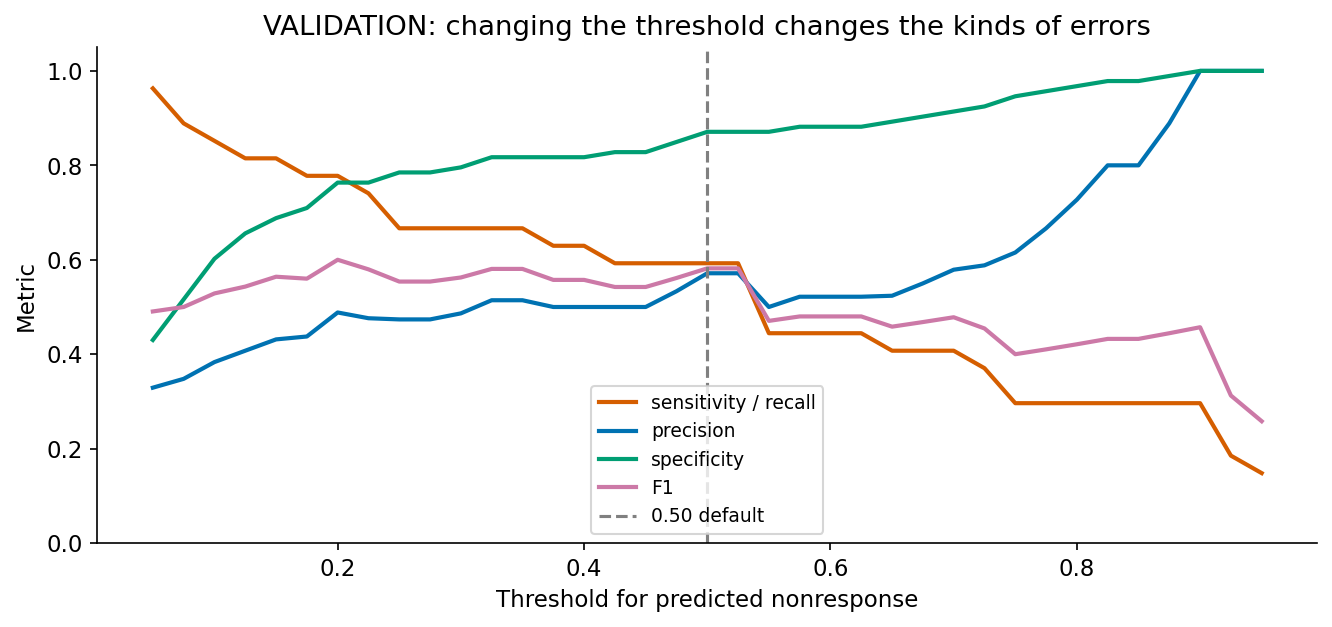

In [ ]:
ths=np.arange(.05,.951,.025)
sweep=pd.DataFrame([{'threshold':t,**metrics(y_val,(val_prob>=t).astype(int))}
                   for t in ths])
fig,ax=plt.subplots(figsize=(9,4.3))
for key,color in [('sensitivity / recall',ORANGE),('precision',BLUE),('specificity',GREEN),('F1',PURPLE)]:
    ax.plot(sweep.threshold,sweep[key],label=key,color=color,linewidth=2)
ax.axvline(.5,color='gray',ls='--',label='0.50 default')
ax.set(xlabel='Threshold for predicted nonresponse',ylabel='Metric',ylim=(0,1.05),
       title='VALIDATION: changing the threshold changes the kinds of errors')
ax.legend(loc='best',fontsize=9)
finish('07_threshold_tradeoff')

**Explain:** Copy TP, FP, FN, precision and sensitivity at thresholds **0.20** and **0.50** from the previous table. If the purpose were to **screen for likely nonresponse**, which might you prefer? If the purpose were to limit unnecessary treatment changes, which might you prefer? Explain in terms of errors, not just F1.

**Your response:** At threshold **0.20**, TP=21, FP=22, FN=6, precision=0.488, and sensitivity=0.778 (TN=71). At **0.50**, TP=16, FP=13, FN=11, precision=0.552, and sensitivity=0.593 (TN=80). For preliminary screening I would lean toward 0.20: it catches five additional Nonresponders and reduces misses from 11 to 6, though it produces nine additional false alarms. If the priority is avoiding unnecessary changes to an effective treatment, I would favor 0.50, since fewer Responders are mislabeled Nonresponders. Neither threshold is clinically justified by this simulation alone.

## 8) ROC vs precision–recall: evaluating ranking across thresholds

The **ROC curve** plots **true positive rate (sensitivity)** against **false positive rate = 1 − specificity** at many thresholds. **ROC-AUC** measures the ability to rank nonresponders above responder ones (0.5 is chance-level ranking for a random score).

The **precision–recall (PR) curve** plots precision versus sensitivity. Its approximate no-skill **horizontal baseline equals the proportion of nonresponders**. **Average precision (AP)** is the stepwise-weighted summary of the PR curve; it is *not exactly* trapezoidal area under that curve. In an imbalanced dataset, PR often makes the burden of false-positive predictions more visible than ROC.

**Predict:** Suppose only ~20% of tumors are Nonresponders. If your classifier identifies most nonresponders but also flags many responder tumors, can its ROC curve still look fairly good while precision is mediocre? What baseline values would you expect for ROC-AUC and AP under random ranking?

**Your response:** I predict ROC-AUC can look reasonably good despite mediocre precision: when Responders greatly outnumber Nonresponders, even a modest false-positive *rate* can generate many false-positive predictions. Random ranking would yield ROC-AUC near 0.50 and average precision near the Nonresponder prevalence (roughly 0.20–0.23), rather than 0.50.

/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Classifier,VALIDATION ROC-AUC,VALIDATION average precision
0,Logistic regression,0.816,0.606
1,RBF SVM,0.825,0.638
2,Random Forest,0.808,0.607


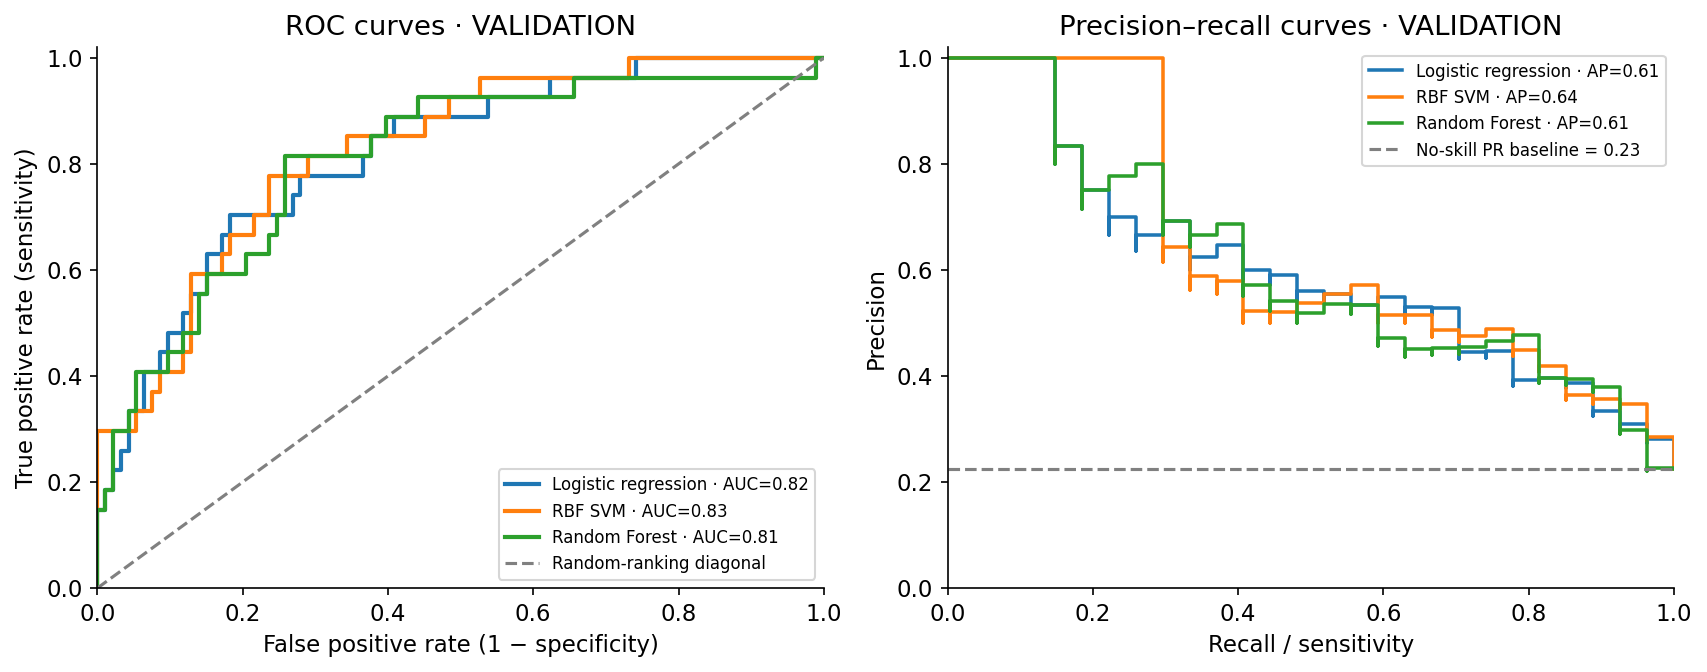

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(11.5,4.6))
pr_rows=[]
for name,grid in searches.items():
    proba=grid.best_estimator_.predict_proba(X_val)[:,1]
    fpr,tpr,_=roc_curve(y_val,proba)
    prec,rec,_=precision_recall_curve(y_val,proba)
    auc=roc_auc_score(y_val,proba)
    ap=average_precision_score(y_val,proba)
    axs[0].plot(fpr,tpr,linewidth=2,label=f'{name} · AUC={auc:.2f}')
    axs[1].step(rec,prec,where='post',linewidth=1.7,label=f'{name} · AP={ap:.2f}')
    pr_rows.append({'Classifier':name,'VALIDATION ROC-AUC':auc,'VALIDATION average precision':ap})
axs[0].plot([0,1],[0,1],ls='--',color='gray',label='Random-ranking diagonal')
axs[0].set(xlabel='False positive rate (1 − specificity)',ylabel='True positive rate (sensitivity)',
           title='ROC curves · VALIDATION',xlim=(0,1),ylim=(0,1.02))
axs[1].axhline(y_val.mean(),ls='--',color='gray',label=f'No-skill PR baseline = {y_val.mean():.2f}')
axs[1].set(xlabel='Recall / sensitivity',ylabel='Precision',title='Precision–recall curves · VALIDATION',
           xlim=(0,1),ylim=(0,1.02))
for ax in axs: ax.legend(fontsize=8,loc='best')
finish('08_roc_vs_precision_recall')
display(pd.DataFrame(pr_rows).round(3))

**Explain:** Identify the highest validation **ROC-AUC** and **average precision**. Does the best model by ROC-AUC necessarily have the best AP or highest F1 at 0.50? Report the **PR baseline** and explain why class prevalence matters for precision. Does either curve establish **calibration** of predicted probabilities?

**Your response:** The RBF SVM led validation ROC-AUC at **0.825** and average precision at **0.638**. Logistic Regression scored ROC-AUC 0.816 and AP 0.606; Random Forest scored 0.808 and AP 0.607. Thus the SVM happened to lead both ranking metrics here, but a higher ROC-AUC does not logically guarantee higher AP or F1 at a particular threshold. The PR baseline was **27/120 = 0.225**, reflecting the Nonresponder prevalence: with a rare positive class, false positives can dominate predicted positives and lower precision. Neither ROC nor PR measures whether a predicted probability such as 0.7 corresponds to a true 70% event rate; calibration would need separate analysis, such as a reliability diagram or Brier score.

## 9) Lock the decision threshold; then open the TEST set **once**

The model family and hyperparameters were chosen by TRAIN-only cross-validation (Section 6). Now choose a threshold on VALIDATION using a fixed candidate list and **validation F1** as a *teaching* objective. In a real study, the threshold must reflect clinical/biological costs and ideally be specified in advance or tuned in an independent validation cohort.

**Do not change your model or threshold after you see the TEST result.** Trying many candidate thresholds can itself overfit the validation set, so the TEST set protects against optimistic selection.

**Predict:** If the held-out test F1 is lower than the validation F1, does that mean the code is wrong? Should you try 10 more thresholds **on the test data** to improve it?

**Your response:** I predict a lower test F1 than validation F1 would not, by itself, indicate a software error; different samples and variability in selection can account for differences. I would **not** try further thresholds or models on the TEST data because that would use the independent assessment set as another tuning set, yielding an overly optimistic final report.

In [ ]:
# Threshold is selected ONLY with validation samples, while the classifier was selected by TRAIN CV.
threshold_grid=np.round(np.arange(.10,.91,.05),2)
threshold_scores=pd.DataFrame([{
    'threshold':float(t),
    'validation_F1':f1_score(y_val,(val_prob>=t).astype(int),zero_division=0)}
    for t in threshold_grid])
chosen_threshold=float(threshold_scores.sort_values(
    ['validation_F1','threshold'],ascending=[False,True]).iloc[0]['threshold'])
chosen_validation_f1=float(threshold_scores['validation_F1'].max())
print('LOCKED MODEL:',chosen_name)
print('LOCKED THRESHOLD:',chosen_threshold)
print('VALIDATION F1:',round(chosen_validation_f1,3))
print('From this point forward, no further model or threshold tuning is permitted.')

LOCKED MODEL: RBF SVM
LOCKED THRESHOLD: 0.2
VALIDATION F1: 0.6
From this point forward, no further model or threshold tuning is permitted.


### Final held-out evaluation

This is the **first** point in the notebook at which we use the TEST labels. A discrepancy between validation and test performance is expected because of sampling variation and imperfect model selection.

HELD-OUT TEST · RBF SVM · threshold 0.2


,accuracy,balanced_accuracy,sensitivity / recall,specificity,precision,F1,TN,FP,FN,TP
0,0.667,0.68,0.704,0.656,0.373,0.487,61,32,8,19


TEST ROC-AUC: 0.802
TEST average precision: 0.702


/tmp/ipykernel_637/4290346086.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


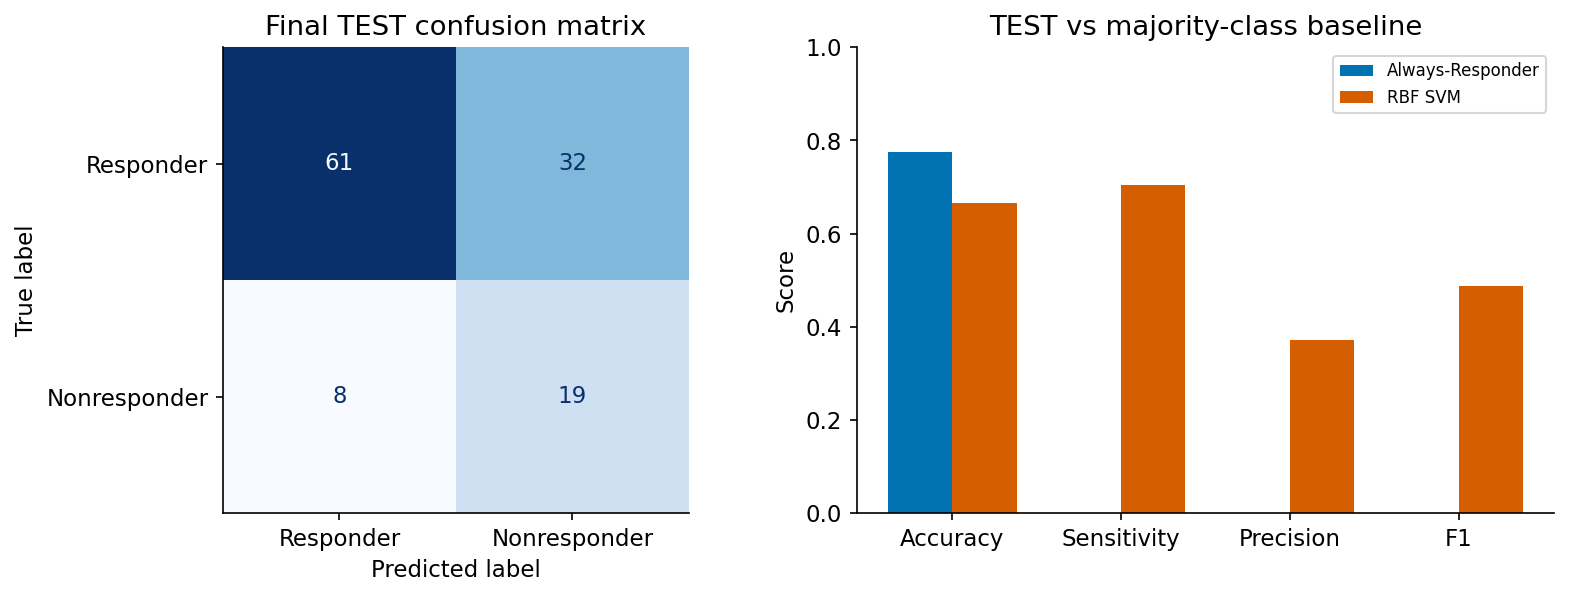

In [ ]:
# One evaluation ONLY: do not use these results to retune.
test_probability=chosen_model.predict_proba(X_test)[:,1]
test_prediction=(test_probability>=chosen_threshold).astype(int)
test_metrics=metrics(y_test,test_prediction)
print('HELD-OUT TEST ·',chosen_name,'· threshold',chosen_threshold)
display(pd.DataFrame([test_metrics]).round(3))
print('TEST ROC-AUC:',round(roc_auc_score(y_test,test_probability),3))
print('TEST average precision:',round(average_precision_score(y_test,test_probability),3))

fig,axs=plt.subplots(1,2,figsize=(11,4.1))
show_cm(axs[0],y_test,test_prediction,'Final TEST confusion matrix')
baseline=metrics(y_test,np.zeros_like(y_test))
keys=['accuracy','sensitivity / recall','precision','F1']
xx=np.arange(len(keys))
axs[1].bar(xx-.19,[baseline[k] for k in keys],width=.38,color=BLUE,label='Always-Responder')
axs[1].bar(xx+.19,[test_metrics[k] for k in keys],width=.38,color=ORANGE,label=chosen_name)
axs[1].set_xticks(xx,['Accuracy','Sensitivity','Precision','F1'])
axs[1].set(ylabel='Score',ylim=(0,1),title='TEST vs majority-class baseline')
axs[1].legend(fontsize=8)
finish('09_final_test')

pd.DataFrame({'sample_id':[f'Tumor_{i+1:03d}' for i in test_idx],
              'actual_nonresponder':y_test,'predicted_probability':test_probability,
              'predicted_nonresponder':test_prediction}).to_csv(
                  OUT/'held_out_test_predictions.csv',index=False)

**Explain:** Record the chosen classifier, hyperparameters, threshold, test **TN/FP/FN/TP**, **sensitivity**, **precision**, **F1**, and **ROC-AUC**. Why would choosing a different model after this output compromise the interpretation of held-out performance? What external validation would be needed before using an assay on real tumors?

**Your response:** The classifier selected by training-only cross-validation was the **RBF SVM**, with **C=0.1**, **gamma=0.001**, and a **validation-chosen threshold of 0.20**. On the untouched 120-tumor TEST set, **TN=61, FP=32, FN=8, TP=19**. Sensitivity was **0.704**, precision **0.373**, F1 **0.487**, ROC-AUC **0.802**, and accuracy **0.667**. The validation F1 used for threshold selection was 0.600, so the lower test F1 reveals a genuine generalization gap rather than proof that the code failed. Selecting another model after seeing this output would turn TEST into model-selection data and invalidate its status as an independent estimate. Before clinical use, we would need external, patient-level validation across laboratories and populations, robust batch-effect and calibration assessments, prospective testing, and evidence that decisions based on the assay improve patient outcomes.

## 10) Interpreting the biology — not just the score

In our simulation, **two latent biological processes** influence both gene expression and tumor responsiveness to treatment, while the technical batch influences a different subset of genes. We know this *only because we constructed the data*. In a real omics study, observed associations alone cannot tell us which gene(s) is/are causal or whether batch, clinical factors, ancestry, repeated samples, or other confounders matter.

**Review:**
- **Clustering vs classification:** PCA/UMAP/t-SNE reveal patterns without labels. Classification predicts **known** response labels. Neither proves that a cluster is a distinct biological subtype.
- **Evaluation:** Training performance is not generalization. CV and validation are for model/threshold selection; the untouched test set estimates performance after decisions are locked.
- **Biological study design:** Patient-level splits prevent replicate leakage. Technical batch, study site, different prevalence and treatment context can all change observed performance.
- **Interpretability:** Logistic Regression coefficients and Random Forest importance reflect fitted *associations*, not gene function or causality.

### Exit ticket — answer all five
1. Explain the biological interpretation of a false negative and false positive when nonresponse is the positive class.
2. Explain how `C` and `gamma` affect an RBF SVM and why CV should select hyperparameters.
3. Why can ROC-AUC look respectable for an imbalanced outcome even when precision is not clinically useful?
4. Does good held-out (test) prediction establish that expression differences cause nonresponse? Name one experimental or external-validation test that would strengthen a biological conclusion.

**Your responses:**

_1._ **Response:** A false negative is a tumor that truly will not respond but is classified as a Responder, potentially leading to ineffective therapy. A false positive is a genuine Responder flagged as a Nonresponder, potentially prompting an unnecessary treatment change or withholding an effective therapy.

_2._ **Response:** In an RBF SVM, larger C penalizes misclassification more strongly, whereas larger gamma gives each sample a narrower, more local influence and allows a more intricate boundary. Cross-validation on training folds compares these choices on unseen fold samples, limiting selection based on training fit alone. The selected C=0.1 and gamma=0.001 had mean CV AP=0.792.

_3._ **Response:** ROC plots sensitivity against false-positive *rate*, which can appear modest even when a large majority class produces many false positives. Precision instead measures the proportion of predicted Nonresponders that are correct and is strongly influenced by the underlying 22.5% positive prevalence; at the chosen test threshold precision was only 0.373 despite ROC-AUC=0.802.

_4._ **Response:** No. Strong held-out prediction establishes an association useful for ranking future simulated samples, not that expression causes resistance. Replicating the expression–outcome association in an independent, prospectively collected treatment cohort would strengthen transportability; perturbing a candidate gene followed by treatment-response assays would more directly test a causal mechanism.

**AI assisted extension / code evaluation:** Ask an AI assistant to suggest one change to an SVM `C`/`gamma` choice, RF leaf-size setting, or classification threshold. First predict how that change should affect TRAIN vs VALIDATION F1 or sensitivity vs precision. Implement one variation using *only training/validation*, and verify the outcome. Do not use TEST data to justify new choices. **In your response, include AI Tool/prompt, prediction, code change, output checked, conclusion.**

_5._ **Response:** **AI tool and prompt:** ChatGPT; “Suggest one validation-only threshold experiment for a binary Nonresponder classifier and predict its effect on sensitivity and precision without consulting test data.” **Suggested variation:** compare thresholds 0.50 and 0.20 on the already trained TRAIN-CV-selected SVM. **Prediction before running:** lowering the threshold should detect more Nonresponders (higher recall) but also generate more false alarms, likely lowering precision. **Implemented code change:** Section 7 already computes `metrics(y_val, (val_prob >= t).astype(int))` for `THRESHOLDS=[.20,.35,.50,.65,.80]`; this explicitly compares `t=.20` against `t=.50` using only VALIDATION observations, without refitting the model. **Output checked:** at 0.50 sensitivity=0.593, precision=0.552, TP=16, FP=13; at 0.20 sensitivity=0.778, precision=0.488, TP=21, FP=22. **Conclusion:** the prediction matched the validation observations: five additional Nonresponders were detected at the cost of nine more false-positive warnings. This is a validation-only demonstration, not permission to revisit model or threshold choices after the locked TEST evaluation.


### References and saved outputs

- [scikit-learn: Pipelines](https://scikit-learn.org/stable/modules/compose.html#pipeline)
- [scikit-learn: Cross-validation and GridSearchCV](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn: SVM documentation](https://scikit-learn.org/stable/modules/svm.html)
- [scikit-learn: Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees)
- [scikit-learn: Precision–recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)

Figures and CSVs are saved to `classifier_outputs` during execution. The `.ipynb` file itself stores code and your written answers. The optional cell below packages figures and CSVs separately.

In [ ]:
import shutil
archive=shutil.make_archive('classifier_outputs','zip',OUT)
print('Created:',archive)
# For Colab downloads, uncomment:
# from google.colab import files
# files.download(archive)

Created: /mnt/data/classifier_outputs.zip
